# PlantaIa — Tarea 2: clasificador en la ESP32

Este notebook implementa y compara los clasificadores de la Tarea 2 y elige el que va a la placa. El contrato (features, target, protocolo, criterio de selección) es [`docs/ENTREGA2.md`](../docs/ENTREGA2.md); el código compartido está en `ml/plantaia_ml/` y el modelo exportado en `firmware/lib/plantaia_ml/modelo_plantaia.h`.

**Qué datos se usan.** Sólo lo que midió la placa: las mediciones de `maceta-01` (snapshot de Railway del 23/10) cruzadas con los episodios de etiqueta de `data/episodios.csv`. Es una sola maceta; las filas del 03/10 al 18/10 quedaron en la base con el identificador `maceta-02` por error y se unifican al leer (`datos_reales.unificar_maceta`). Los días sin registro quedan como huecos: no se completan ni se interpolan. Son 24 episodios (4 de ellos de etiqueta dudosa), así que **el N efectivo son los episodios**, no las filas, y todas las métricas llevan su incertidumbre (bootstrap por episodio).

**Versión anterior.** Con el snapshot del 21/10 (sin el tramo del 03/10 al 18/10, 11 episodios) nada generalizaba por episodio (F1 macro ≈ 0,3) y el modelo de la placa era `arbol-p2-f012-58e644`. Esta ejecución lo reemplaza; los números viejos quedan en el historial de git.

**Restricción de diseño (decisión de producto).** El semáforo de la placa no puede depender sólo de la sonda de suelo: todo candidato con selección de features usa `suelo_mv` **y al menos una variable ambiental del aire** (T, HR o VPD). **La luz no entra** (`luz_mv`, `luz_media_1h`): se decidió con el snapshot del 21/10, donde la marchita sólo se observó de noche y con la luz el modelo aprendía "oscuro → marchita". Se mantiene; §6.3 muestra qué pasa ahora con la luz. Los baselines de umbral sobre `suelo_mv` quedan como referencia. Además, dos condiciones de producto: la ambiental tiene que cambiar la clase de ≥ 1 % de las filas (§5.5), y el modelo no puede perder la marchita (§5.6: recall de marchita ≥ 0,9 sin dudosos y el ep. 12 bien). La §5.7 verifica que la ambiental cambia predicciones y compara con un modelo sólo-suelo.

**Re-ejecución.** El código no tiene números fijos: `jupyter nbconvert --to notebook --execute --inplace notebooks/03_modelos.ipynb`. La §5.5 avisa si la selección ya no coincide con `CONFIG_FINAL` o si el header exportado quedó viejo, y la §7 reescribe `docs/entrega2/tablas_03_modelos.md` con todas las tablas. Los comentarios en texto describen la ejecución commiteada.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import export_text, plot_tree

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml" / "plantaia_ml").is_dir())
sys.path.insert(0, str(RAIZ / "ml"))

from plantaia_ml import CLASES, FIGURAS, SNAPSHOT_VIGENTE
from plantaia_ml.dataset import serie_maceta01
from plantaia_ml.datos_reales import EPISODIOS_DUDOSOS
from plantaia_ml.exportar_c import RUTA_MODELO, bytes_parametros_c, version_modelo
from plantaia_ml.features import FEATURES
from plantaia_ml.modelos import (AMBIENTALES, COLUMNAS_NO_FEATURES, CONFIG_FINAL, EP_MARCHITA_OCTUBRE,
                                 MIN_ACIERTO_EP12, MIN_CAMBIO_PCT, MIN_RECALL_MARCHITA,
                                 configuraciones_seguridad, K_EXTERNO,
                                 K_INTERNO, SUBCONJUNTOS, baselines, busqueda, candidatos,
                                 costo_esp32, cumple_restriccion, matriz_X, modelo_final,
                                 nombre_subconjunto, particion_externa, particion_interna)
from plantaia_ml.modelos import UmbralesOrdenados

warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import FitFailedWarning
# Con pocos episodios algunos folds internos quedan con una sola clase: esas configuraciones
# puntúan NaN en ese fold (modelos.busqueda) en vez de cortar la ejecución.
warnings.filterwarnings("ignore", category=FitFailedWarning)
warnings.filterwarnings("ignore", category=UserWarning)           # f1 con clases ausentes en un fold
warnings.filterwarnings("ignore", message=".*ill-defined.*")
warnings.filterwarnings("ignore", message=".*Stochastic Optimizer.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA_TABLAS = RAIZ / "docs" / "entrega2" / "tablas_03_modelos.md"
print("snapshot:", SNAPSHOT_VIGENTE.relative_to(RAIZ))

COLORES = {"saludable": "#4c9f70", "estresada": "#e6a23c", "marchita": "#c84b4b"}
CODIGOS = [1, 2, 3]


def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")
    print(f"figura: docs/entrega2/fig/{nombre}")

snapshot: data/mediciones_raw_2026-10-23.csv


## 1. Datos

`serie_maceta01()` arma la serie de la maceta a 5 min: remuestrea el dato de la placa (casi todo quedó a 30 s; el tramo del 03/10 al 18/10 ya viene a 5 min) con la mediana por bin, cruza cada fila con su episodio de `data/episodios.csv`, calcula las features como las calcularía la placa y recién después filtra: fuera los primeros 60 min tras cada arranque (transitorio de la sonda), la sonda saturada, las filas sin vector completo y las que no caen en ningún episodio.

### Qué entra al modelo y qué no (*drop* de etiquetas)

La tabla de modelado trae, además de las 7 features, la etiqueta y **de dónde salió**: la clase en texto, `etiqueta_origen` (`manual`, `propagada`, `corregida`), la marca `dudoso`, el `episodio_id`, las marcas de calidad (`warmup`, `valido`, `post_boot`, …) y la hora. Ninguna de esas columnas existe en la placa, y varias están **correlacionadas con la etiqueta por cómo se armó el dato** (por ejemplo, todas las filas de un episodio dudoso son de la misma clase). Si entraran a `X`, el modelo podría aprender la procedencia de la etiqueta en vez de la condición de la planta.

Por eso `X` se arma **descartando explícitamente** esas columnas, y un `assert` exige que lo que queda sea exactamente el contrato §4 (las 7 features, en orden). `y` es `clase_codigo`; `episodio_id` se usa **sólo** como grupo de la partición y `dudoso` **sólo** para reportar con y sin los episodios de etiqueta débil. El exportador usa el mismo resguardo (`modelos.matriz_X`).

In [2]:
df = serie_maceta01()

# X: se descartan EXPLÍCITAMENTE todas las columnas que no son features (etiqueta y su procedencia,
# identificación, tiempo, marcas de calidad) antes de cualquier fit. Ver la explicación arriba.
METADATOS = ["ts", "dispositivo", "boot_id", "tramo",                 # identificación y tiempo
             "clase", "clase_codigo", "etiqueta_origen", "dudoso",    # la etiqueta y de dónde salió
             "episodio_id",                                           # grupo de la partición
             "warmup", "valido", "post_boot", "suelo_saturado",       # marcas de calidad
             "errores", "marcas", "temp_ntc_c"]                       # termistor: fuera del contrato §4
# Columnas de procedencia que la tabla hoy no trae pero que nunca pueden entrar a X si aparecen.
METADATOS_SI_APARECEN = ["etiqueta", "origen", "nota", "flags", "muestra_id", "ts_iso", "ts_unix"]
assert set(METADATOS + METADATOS_SI_APARECEN) == set(COLUMNAS_NO_FEATURES), "misma lista que modelos.matriz_X"
X_df = df.drop(columns=METADATOS + [c for c in METADATOS_SI_APARECEN if c in df.columns])
assert sorted(X_df.columns) == sorted(FEATURES), f"X tiene columnas fuera del contrato §4: {list(X_df.columns)}"
X_df = X_df[FEATURES]
assert list(X_df.columns) == FEATURES                    # exactamente el contrato §4, en su orden
X = X_df.to_numpy(np.float32)      # float32, como la placa y como sklearn recorre los árboles
assert np.array_equal(X, matriz_X(df)), "el resguardo de modelos.py (lo usa el exportador) da lo mismo"
y = df.clase_codigo.to_numpy(int)                 # target: código del firmware 1..3
g = df.episodio_id.to_numpy(int)                  # SÓLO como grupo de la partición por episodio
dudoso = df.dudoso.to_numpy(bool)                 # SÓLO para reportar con y sin dudosos
sin_dud = ~dudoso
TODAS = np.ones(len(y), bool)
print("X:", X.shape, "columnas:", list(X_df.columns))
print(f"filas: {len(df):,} · episodios: {df.episodio_id.nunique()} (sin dudosos: {df[sin_dud].episodio_id.nunique()}) · "
      f"desde {df.ts.min():%d/%m %H:%M} hasta {df.ts.max():%d/%m %H:%M} UTC")

filas_conteo = {}
for c in CLASES + ["total"]:
    dc = df if c == "total" else df[df.clase == c]
    filas_conteo[c] = {("todos", "filas"): len(dc), ("todos", "episodios"): dc.episodio_id.nunique(),
                       ("sin dudosos", "filas"): int((~dc.dudoso).sum()),
                       ("sin dudosos", "episodios"): dc[~dc.dudoso].episodio_id.nunique()}
tabla_conteo = pd.DataFrame(filas_conteo).T
display(tabla_conteo)
print("proporción de filas por clase:", (df.clase.value_counts(normalize=True).reindex(CLASES)
                                         .round(3).to_dict()))

X: (5663, 7) columnas: ['suelo_mv', 'suelo_delta_1h', 'temp_c', 'hum_aire_pct', 'vpd_kpa', 'luz_mv', 'luz_media_1h']
filas: 5,663 · episodios: 24 (sin dudosos: 20) · desde 13/09 00:55 hasta 21/10 21:20 UTC


todos           sin dudosos          
          filas episodios       filas episodios
saludable  2452         7        2425         6
estresada  2446        11        2092         9
marchita    765         6         654         5
total      5663        24        5171        20

proporción de filas por clase: {'saludable': 0.433, 'estresada': 0.432, 'marchita': 0.135}


Las filas son más de cinco mil pero **no son independientes**: dentro de un episodio todas comparten etiqueta y las contiguas están a 5 min. El N que importa para todo lo que sigue es el de **episodios** (24; 20 sin dudosos).

Tabla de los episodios (agregados por episodio; los dudosos son los de `EPISODIOS_DUDOSOS`, con el motivo en `data/episodios.csv`):

In [3]:
tabla_ep = (df.groupby("episodio_id")
            .agg(clase=("clase", "first"), origen=("etiqueta_origen", "first"),
                 dudoso=("dudoso", "first"), filas=("ts", "size"),
                 desde=("ts", "min"), suelo_mv_mediana=("suelo_mv", "median"),
                 temp_c_mediana=("temp_c", "median"), luz_mv_mediana=("luz_mv", "median")))
tabla_ep["desde"] = tabla_ep.desde.dt.strftime("%d/%m %H:%M")
display(tabla_ep)
for k, v in EPISODIOS_DUDOSOS.items():
    print(f"dudoso {k}: {v}")

,clase,origen,dudoso,filas,desde,suelo_mv_mediana,temp_c_mediana,luz_mv_mediana
episodio_id,,,,,,,,
1,marchita,corregida,False,132,13/09 00:55,"2,832.000",8.500,189.250
3,estresada,manual,False,24,15/09 13:35,"2,766.500",34.200,"2,037.500"
6,estresada,manual,False,74,16/09 17:55,"2,048.000",14.600,"2,892.250"
8,marchita,manual,True,111,01/10 01:40,"1,518.000",20.600,142.000
9,estresada,manual,True,52,01/10 10:55,"1,454.000",19.000,"2,299.500"
10,saludable,manual,False,140,02/10 01:55,"1,504.000",18.600,"1,976.750"
11,saludable,propagada,True,27,19/10 00:35,"1,785.500",20.200,142.000
12,marchita,manual,False,90,19/10 02:50,"1,758.000",20.200,142.000
13,estresada,manual,False,146,19/10 10:20,"1,927.000",19.400,"1,674.500"


dudoso 8: marchita con el sustrato igual que saludable (~1550 mV), nocturna
dudoso 9: estresada con el sustrato en ~1454 mV, el rango de los saludable de octubre
dudoso 11: propagada de Preferences 16 días después; contradicha por la observación siguiente
dudoso 14: estresada propagada ~25 h después de un riego, sin nadie que la confirme


figura: docs/entrega2/fig/serie_modelado.png


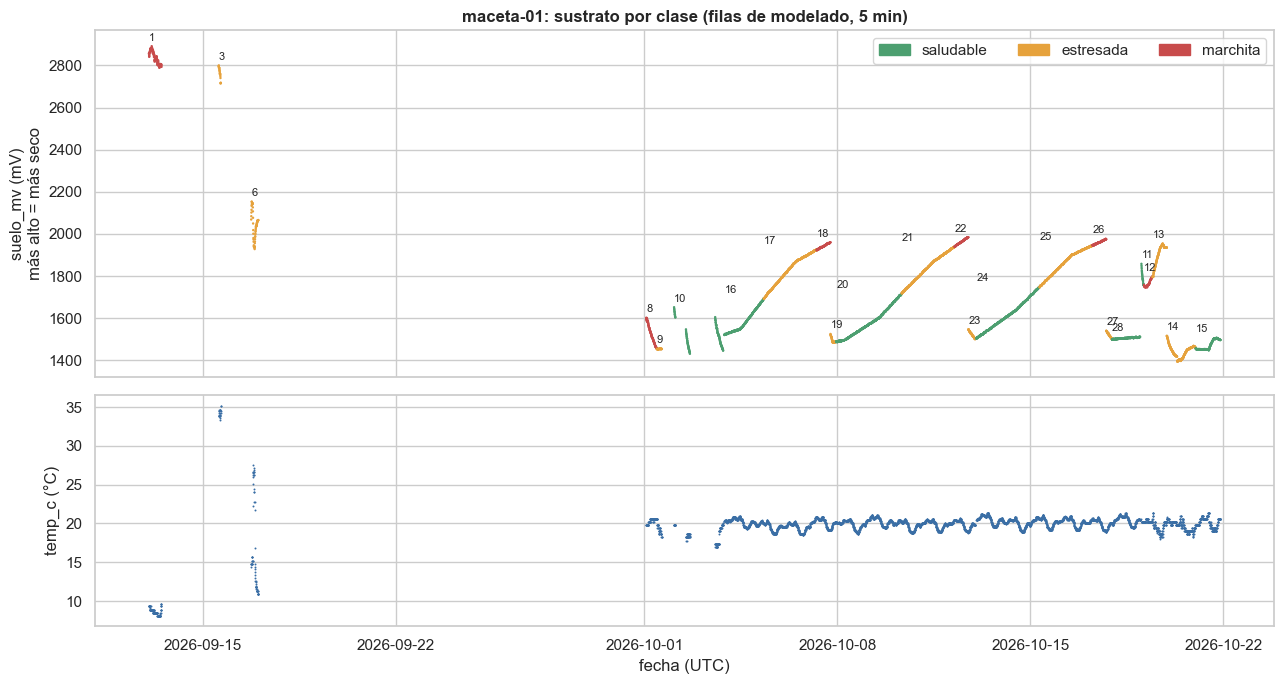

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.scatter(df.ts, df.suelo_mv, s=3, c=df.clase.map(COLORES), lw=0, rasterized=True)
ax.set_ylabel("suelo_mv (mV)\nmás alto = más seco")
ax.set_title("maceta-01: sustrato por clase (filas de modelado, 5 min)", fontweight="bold")
ax.legend(handles=[Patch(color=COLORES[c], label=c) for c in CLASES], ncol=3, loc="upper right")
for e, d in df.groupby("episodio_id"):
    ax.annotate(str(e), (d.ts.min(), d.suelo_mv.max()), textcoords="offset points", xytext=(0, 4), fontsize=8)
ax = axes[1]
ax.scatter(df.ts, df.temp_c, s=2, c="#3a6ea5", lw=0, rasterized=True)
ax.set_ylabel("temp_c (°C)")
ax.set_xlabel("fecha (UTC)")
fig.tight_layout()
guardar(fig, "serie_modelado.png")
plt.show()

**Lo que se ve.**

- **Dónde hay dato.** 13–17/09 y del 01/10 al 21/10, con un hueco grande del 17/09 al 01/10.
- **Del 03/10 al 18/10 hay tres ciclos completos** de ~5 días (eps. 16–28): saludable → estresada (el sustrato se seca de ~1500 a ~1900 mV) → marchita 12 h **de día** → riego a las 18:00 UTC (cae ~435 mV) → estresada 5–6 h de recuperación (eps. 19, 23, 27, con el sustrato ya mojado) → saludable.
- **La escala de la sonda se corre entre meses.** En septiembre la `marchita` (ep. 1) marcaba ~2830 mV; en octubre ~1940–1960 mV en los ciclos del 03/10 al 18/10 y ~1758 mV en el ep. 12 del 19/10.
- **Septiembre tiene otro ambiente.** El ep. 1 es frío (~8,5 °C) y el ep. 3 es sobre el radiador (~34 °C). En octubre la temperatura queda en 18–22 °C.
- **Episodios perdidos.** El corte de 60 min tras cada arranque elimina enteros algunos episodios cortos de septiembre (`AUDITORIA_DATOS.md`, H7): por eso faltan los ids 2, 4, 5 y 7.

## 2. Preparación, features y target

**Features** (contrato §4, mismo código en Python y en C, con test de paridad): se calculan cada 5 min con la muestra actual y un buffer de 13 muestras (1 h). La placa arma siempre los 7 en este orden; si el modelo usa menos, el exportador remapea índices.

| idx | feature | qué es |
|---|---|---|
| 0 | `suelo_mv` | sonda resistiva, mediana de 9 (mV; más alto = más seco) |
| 1 | `suelo_delta_1h` | `suelo_mv(t) − suelo_mv(t−1 h)`; 0 en warm-up |
| 2 | `temp_c` | DHT11 (último válido si falla) |
| 3 | `hum_aire_pct` | DHT11 |
| 4 | `vpd_kpa` | déficit de presión de vapor (Tetens) con 2 y 3 |
| 5 | `luz_mv` | LDR, mediana de 9 |
| 6 | `luz_media_1h` | media de `luz_mv` en la última hora |

**Fuera a propósito**: la hora del día (está confundida con el horario del observador, §6.3), `luz_pct`/`suelo_pct` (sin calibrar) y el termistor (su conversión en el firmware 1.1.0 está invertida).

**Target**: códigos del firmware 1 `saludable`, 2 `estresada`, 3 `marchita`. `sin_etiquetar` (0) no es clase: las filas sin episodio ya quedaron afuera en el filtrado. Las filas de warm-up (primera hora de cada tramo) **se quedan**: la placa también infiere en esa hora, con `suelo_delta_1h = 0`.

In [5]:
assert set(np.unique(y)) == {1, 2, 3}, "el target tiene que ser exactamente 1..3"
assert not df.clase.isin(["sin_etiquetar"]).any() and df.episodio_id.notna().all()
assert np.isfinite(X).all(), "no puede haber NaN en el vector (la placa no infiere sin vector completo)"
print(f"filas en warm-up (suelo_delta_1h = 0): {df.warmup.sum():,} ({df.warmup.mean():.1%})")

resumen = pd.concat({"todos": df.groupby("clase")[FEATURES].median(),
                     "sin dudosos": df[sin_dud].groupby("clase")[FEATURES].median()}, axis=1)
resumen = resumen.reindex(CLASES).T.swaplevel().sort_index(level=0, sort_remaining=False)
resumen = resumen.reindex(FEATURES, level=0)
print("Mediana de cada feature por clase (todos los episodios y sin dudosos):")
display(resumen)

filas en warm-up (suelo_delta_1h = 0): 25 (0.4%)
Mediana de cada feature por clase (todos los episodios y sin dudosos):


clase                       saludable  estresada  marchita
suelo_mv       todos        1,550.000  1,826.000 1,952.000
               sin dudosos  1,549.000  1,852.000 1,956.000
suelo_delta_1h todos            3.000      4.000     2.000
               sin dudosos      3.000      5.000     3.000
temp_c         todos           20.200     19.900    20.200
               sin dudosos     20.200     19.900    20.200
hum_aire_pct   todos           48.000     47.000    47.000
               sin dudosos     48.000     47.000    46.000
vpd_kpa        todos            1.231      1.216     1.255
               sin dudosos      1.231      1.216     1.278
luz_mv         todos          973.000  1,201.000   277.500
               sin dudosos    991.000  1,189.000   746.500
luz_media_1h   todos        1,003.038  1,192.962   252.154
               sin dudosos  1,021.385  1,184.019   362.423

**Lectura de las medianas.**

- **`suelo_mv` ordena las clases** con y sin dudosos (sin dudosos: saludable 1549 < estresada 1852 < marchita 1956 mV). Con el snapshot del 21/10 no las ordenaba: los episodios del 03/10 al 18/10, cuyas etiquetas siguen al sustrato, cambian el panorama.
- **T, HR y VPD casi no cambian entre clases** (~20 °C, ~47 %, ~1,2 kPa): en octubre el ambiente fue estable. La ambiental sólo puede aportar en los bordes (frío o radiador de septiembre).
- **La luz baja en la marchita** (mediana 278 mV con todos, 747 sin dudosos), pero mucho menos que antes: las marchitas del 03/10 al 18/10 son diurnas.

## 3. Protocolo de evaluación

* **Partición externa por episodio**: `StratifiedGroupKFold` con k = 5 y `episodio_id` como grupo. Un episodio entero cae en train o en test, nunca partido. Con 24 episodios cada fold de test tiene 4 o 5, y no siempre están las tres clases.
* **Búsqueda de hiperparámetros anidada**: dentro de cada fold externo, `GridSearchCV` con otra partición por episodio (k = 3) sobre el train, maximizando F1 macro. Si un fold interno queda con una sola clase, esa configuración puntúa NaN ahí. El subconjunto de features es un hiperparámetro más, **restringido** a `suelo_mv` + al menos una ambiental: suelo + cada ambiental, suelo + delta + cada ambiental, suelo + cada par de ambientales, y `sin luz` (suelo, delta, T, HR, VPD): 10 subconjuntos, ninguno con luz (§6.3). El fold externo no participa de la elección.
* **Métricas sobre las predicciones fuera de fold juntas.** Como los folds de test tienen pocos episodios y no siempre las tres clases, una métrica por fold no se puede promediar. Se juntan las predicciones fuera de fold de los 5 folds (cada fila predicha por un modelo que no vio su episodio) y se calcula una sola vez: exactitud balanceada (el azar con 3 clases es 0,33), F1 macro, recall de `marchita` (el error caro es no avisar) y ROC-AUC OvR cuando el modelo da probabilidades. **El desvío sale de un bootstrap por episodio**: se remuestrean los episodios (estratificado por clase, 500 veces) y se recalcula la métrica.
* Cada métrica se reporta **con todos los episodios y sin los dudosos**. La selección usa "sin dudosos".

### ¿Por qué no un split aleatorio?

Las filas contiguas comparten etiqueta y son casi iguales. Con un split aleatorio, cada fila de test tiene a su vecina de 5 min en train: el modelo puede "reconocer el episodio" en vez de la condición de la planta. Mismo modelo y mismos datos, dos particiones:

In [6]:
from sklearn.ensemble import RandomForestClassifier


def bosque_todas():
    # Random Forest con las 7 features, sin búsqueda: el más capaz de memorizar episodios.
    return candidatos()["Random Forest"][0].set_params(sel__columnas=tuple(range(len(FEATURES))),
                                                       clf__max_depth=8, clf__min_samples_leaf=20)


def comparar_particiones(est, X_, y_, g_):
    out = {}
    for nombre, cv, grupos in [("aleatoria (filas mezcladas)",
                                StratifiedKFold(K_EXTERNO, shuffle=True, random_state=0), None),
                               ("por episodio", particion_externa(), g_)]:
        oof_ = np.zeros(len(y_), int)
        for tr, te in cv.split(X_, y_, grupos):
            oof_[te] = clone(est).fit(X_[tr], y_[tr]).predict(X_[te])
        out[nombre] = balanced_accuracy_score(y_, oof_)
    return out


fuga = pd.DataFrame({"RF 7 features": comparar_particiones(bosque_todas(), X, y, g)}).T
fuga.columns.name = "exactitud balanceada (fuera de fold, 5 folds)"
display(fuga)

"exactitud balanceada (fuera de fold, 5 folds)",aleatoria (filas mezcladas),por episodio
RF 7 features,0.968,0.646


**La fuga sigue siendo grande.** El mismo Random Forest da 0,968 de exactitud balanceada con filas mezcladas y 0,646 por episodio. Ahora la partición por episodio sí queda muy por encima del azar (0,33): con 24 episodios hay algo generalizable, pero un tercio del número del split aleatorio es fuga.

Todo lo que sigue usa partición por episodio. El N efectivo es de 24 episodios (20 sin dudosos).

## 4. Baselines y candidatos

**Baselines obligatorios** (sin búsqueda; se ajustan en el train de cada fold):

* *Clase mayoritaria*: siempre `saludable`.
* *Umbral único sobre `suelo_mv`*: un tocón (árbol de profundidad 1). Con un solo corte predice como mucho dos clases: es el baseline literal del plan.
* *Dos umbrales sobre `suelo_mv`*: la regla ordinal que pondría alguien mirando el histograma (`suelo ≤ t1` saludable, `≤ t2` estresada, si no marchita), con t1 y t2 elegidos en el train por F1 macro. Es el rival honesto: cualquier modelo que no le gane no justifica su complejidad.

**Candidatos** (§5.2, grillas en `ml/plantaia_ml/modelos.py`): regresión logística, árbol de decisión (prof. ≤ 8), Random Forest (30 árboles, prof. ≤ 8), Naive Bayes gaussiano, k-NN, SVM RBF y MLP chico. `class_weight="balanced"` donde existe (hay ~2 filas `saludable` por cada `marchita`). Todos eligen su subconjunto dentro del espacio restringido (suelo + ≥ 1 ambiental); los baselines usan sólo `suelo_mv` y no son elegibles.

In [7]:
N_BOOT = 500


def f1m(y_, p_):
    return f1_score(y_, p_, labels=CODIGOS, average="macro", zero_division=0)


def recall_marchita(y_, p_):
    return recall_score(y_, p_, labels=[3], average="macro", zero_division=0)


def remuestras_por_episodio(mascara, n=N_BOOT, semilla=0):
    # Bootstrap por episodio estratificado por clase: índices de filas de cada remuestra.
    ep = df[mascara].groupby("episodio_id").clase.first()
    filas = {e: np.flatnonzero(mascara & (g == e)) for e in ep.index}
    rng = np.random.default_rng(semilla)
    out = []
    for _ in range(n):
        eps = np.concatenate([rng.choice(ep[ep == c].index, size=(ep == c).sum(), replace=True)
                              for c in CLASES if (ep == c).any()])
        out.append(np.concatenate([filas[e] for e in eps]))
    return out


MASCARAS_EV = {"todos": TODAS, "sin dudosos": sin_dud}
REMUESTRAS = {k: remuestras_por_episodio(m) for k, m in MASCARAS_EV.items()}
METRICAS_FN = {"exactitud_bal": balanced_accuracy_score, "f1_macro": f1m, "recall_marchita": recall_marchita}


def metricas(pred, proba=None):
    # Métricas sobre las predicciones fuera de fold juntas, con su desvío bootstrap por episodio.
    out = {}
    for mk, m in MASCARAS_EV.items():
        for met, fn in METRICAS_FN.items():
            out[(mk, met)] = fn(y[m], pred[m])
            out[(mk, f"{met} (desvío)")] = np.std([fn(y[i], pred[i]) for i in REMUESTRAS[mk]])
        out[(mk, "roc_auc_ovr")] = (roc_auc_score(y[m], proba[m], multi_class="ovr", average="macro", labels=CODIGOS)
                                    if proba is not None and np.isfinite(proba[m]).all() else np.nan)
    return out


def proba_3(modelo, X_):
    # predict_proba con las columnas 1..3 aunque el train no haya visto alguna clase.
    try:
        p = modelo.predict_proba(X_)
    except AttributeError:
        return None
    out = np.zeros((len(X_), 3))
    for j, c in enumerate(modelo.classes_):
        out[:, CODIGOS.index(int(c))] = p[:, j]
    return out


def evaluar(est, grilla, cv=None, n_jobs=-1):
    # Evaluación por episodio; con grilla, búsqueda anidada. Devuelve predicciones fuera de fold y métricas.
    cv = cv or particion_externa()
    elegidos = []
    oof = np.zeros(len(y), int)
    oof_p = np.full((len(y), 3), np.nan)
    for tr, te in cv.split(X, y, g):
        if grilla:
            b = busqueda(est, grilla, n_jobs=n_jobs).fit(X[tr], y[tr], groups=g[tr])
            modelo = b.best_estimator_
            elegidos.append(b.best_params_)
        else:
            modelo = clone(est).fit(X[tr], y[tr])
            elegidos.append({})
        oof[te] = modelo.predict(X[te])
        p = proba_3(modelo, X[te])
        if p is not None:
            oof_p[te] = p
    return {"oof": oof, "oof_p": oof_p, "elegidos": elegidos,
            "metricas": metricas(oof, oof_p if np.isfinite(oof_p).all() else None)}


MODELOS = {**baselines(), **candidatos()}
ES_BASELINE = {n: n in baselines() for n in MODELOS}
resultados, tiempos = {}, {}
for nombre, (est, grilla) in MODELOS.items():
    t0 = time.perf_counter()
    resultados[nombre] = evaluar(est, grilla)
    tiempos[nombre] = time.perf_counter() - t0
    print(f"{nombre:<26} {tiempos[nombre]:6.1f} s")

Clase mayoritaria             1.9 s


Umbral único (suelo_mv)       1.9 s


Dos umbrales (suelo_mv)       2.1 s


Regresión logística           6.1 s


Árbol de decisión             2.9 s


Random Forest                 5.9 s


Naive Bayes                   2.2 s


k-NN                          4.1 s


SVM RBF                      10.0 s


MLP                          11.5 s


In [8]:
METRICAS = ["exactitud_bal", "f1_macro", "recall_marchita"]


def tabla_metricas(res_por_modelo):
    filas = {}
    for n, r in res_por_modelo.items():
        m = r["metricas"]
        filas[n] = {(mk, met): f"{m[(mk, met)]:.3f} ± {m[(mk, met + ' (desvío)')]:.3f}"
                    for mk in MASCARAS_EV for met in METRICAS}
        for mk in MASCARAS_EV:
            filas[n][(mk, "roc_auc_ovr")] = f"{m[(mk, 'roc_auc_ovr')]:.3f}" if np.isfinite(m[(mk, "roc_auc_ovr")]) else "n/d"
    return pd.DataFrame(filas).T


print(f"{df.episodio_id.nunique()} episodios · StratifiedGroupKFold k={K_EXTERNO} · predicciones fuera de fold "
      f"juntas (± desvío bootstrap por episodio)")
tabla_cv = tabla_metricas(resultados)
display(tabla_cv)
resumen_cv = pd.DataFrame({n: r["metricas"] for n, r in resultados.items()}).T

24 episodios · StratifiedGroupKFold k=5 · predicciones fuera de fold juntas (± desvío bootstrap por episodio)


todos                                   sin dudosos                                      todos sin dudosos
                         exactitud_bal       f1_macro recall_marchita  exactitud_bal       f1_macro recall_marchita roc_auc_ovr roc_auc_ovr
Clase mayoritaria        0.192 ± 0.076  0.151 ± 0.055   0.000 ± 0.000  0.165 ± 0.082  0.128 ± 0.061   0.000 ± 0.000       0.376       0.352
Umbral único (suelo_mv)  0.456 ± 0.073  0.421 ± 0.079   0.188 ± 0.158  0.482 ± 0.090  0.461 ± 0.091   0.220 ± 0.195       0.703       0.785
Dos umbrales (suelo_mv)  0.742 ± 0.078  0.751 ± 0.075   0.609 ± 0.176  0.818 ± 0.067  0.822 ± 0.060   0.713 ± 0.159         n/d         n/d
Regresión logística      0.547 ± 0.062  0.529 ± 0.054   0.370 ± 0.155  0.594 ± 0.068  0.578 ± 0.053   0.433 ± 0.178       0.690       0.786
Árbol de decisión        0.719 ± 0.074  0.711 ± 0.068   0.625 ± 0.176  0.792 ± 0.064  0.779 ± 0.054   0.731 ± 0.158       0.771       0.834
Random Forest            0.655 ± 0.063  0.634 ± 0.060   0.557 ± 0.146  0.718 ± 0.057  0.692 ± 0.052   0.651 ± 0.130       0.803       0.876
Naive Bayes              0.380 ± 0.069  0.371 ± 0.072   0.000 ± 0.000  0.401 ± 0.076  0.408 ± 0.072   0.000 ± 0.000       0.587       0.653
k-NN                     0.691 ± 0.061  0.688 ± 0.058   0.475 ± 0.163  0.739 ± 0.063  0.734 ± 0.058   0.555 ± 0.181       0.824       0.864
SVM RBF                  0.625 ± 0.072  0.597 ± 0.066   0.544 ± 0.187  0.665 ± 0.081  0.628 ± 0.072   0.636 ± 0.208         n/d         n/d
MLP                      0.542 ± 0.067  0.540 ± 0.071   0.186 ± 0.156  0.589 ± 0.073  0.590 ± 0.074   0.217 ± 0.192       0.665       0.742

**Hiperparámetros que eligió la búsqueda interna en cada fold externo.** Si cambian mucho de un fold a otro, la elección es inestable (otra señal de pocos episodios).

In [9]:
def describir(params):
    if not params:
        return "—"
    sub = nombre_subconjunto(params.get("sel__columnas", ()))
    resto = ", ".join(f"{k.split('__')[1]}={v}" for k, v in params.items() if k != "sel__columnas")
    return f"[{sub}] {resto}".strip()


display(pd.DataFrame({n: [describir(p) for p in r["elegidos"]] for n, r in resultados.items()
                      if not ES_BASELINE[n]}, index=[f"fold {i + 1}" for i in range(K_EXTERNO)]).T)

,fold 1,fold 2,fold 3,fold 4,fold 5
Regresión logística,[suelo+delta+hr] C=0.1,[sin luz] C=0.1,[suelo+vpd] C=0.01,[suelo+delta+hr] C=0.1,[suelo+vpd] C=1.0
Árbol de decisión,"[suelo+hr] max_depth=2, min_samples_leaf=20","[suelo+delta+temp] max_depth=2, min_samples_le...","[suelo+hr] max_depth=2, min_samples_leaf=20","[suelo+temp] max_depth=2, min_samples_leaf=20","[suelo+delta+temp] max_depth=8, min_samples_le..."
Random Forest,"[suelo+vpd] max_depth=8, min_samples_leaf=100","[suelo+delta+hr] max_depth=5, min_samples_leaf...","[sin luz] max_depth=8, min_samples_leaf=100","[suelo+hr] max_depth=3, min_samples_leaf=20","[suelo+vpd] max_depth=8, min_samples_leaf=100"
Naive Bayes,[suelo+delta+vpd],[suelo+hr],[suelo+vpd],[suelo+hr],[suelo+vpd]
k-NN,[suelo+delta+hr] n_neighbors=101,[sin luz] n_neighbors=25,[sin luz] n_neighbors=25,[sin luz] n_neighbors=5,[suelo+delta+hr] n_neighbors=5
SVM RBF,[suelo+delta+temp] C=1.0,[suelo+delta+temp] C=1.0,[suelo+delta+hr] C=10.0,[suelo+delta+hr] C=10.0,[suelo+delta+hr] C=10.0
MLP,"[sin luz] alpha=0.1, hidden_layer_sizes=(16, 8)","[sin luz] alpha=0.1, hidden_layer_sizes=(8,)","[sin luz] alpha=0.001, hidden_layer_sizes=(16, 8)","[suelo+temp] alpha=0.1, hidden_layer_sizes=(16...","[suelo+delta+vpd] alpha=0.001, hidden_layer_si..."


figura: docs/entrega2/fig/comparacion_modelos.png


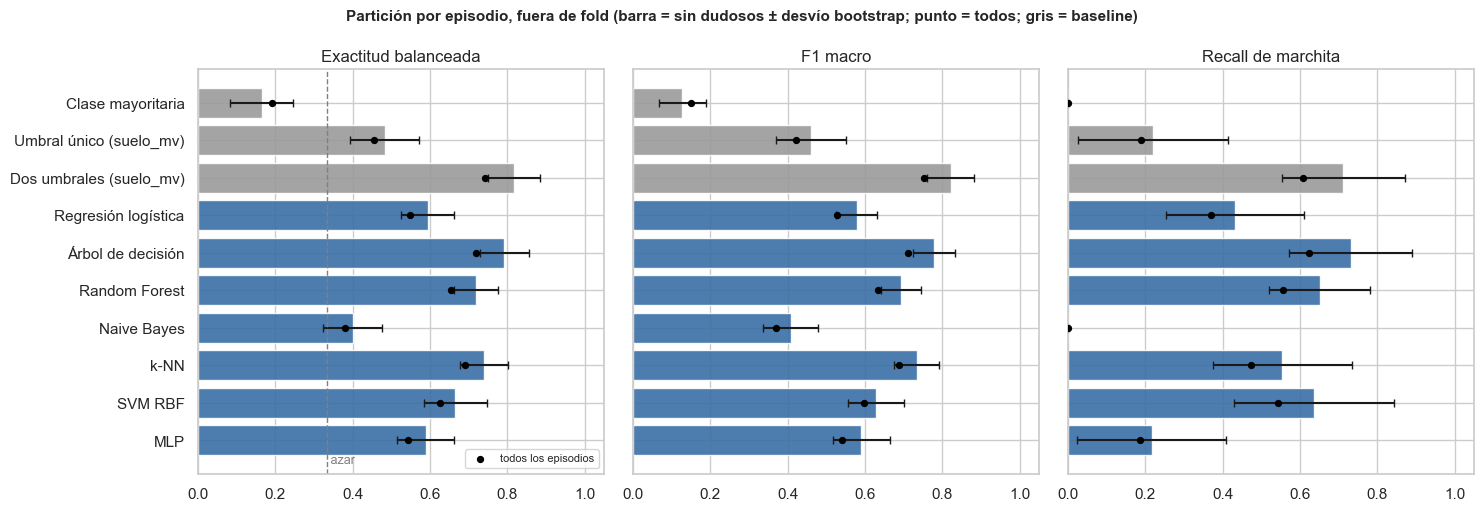

In [10]:
orden = list(MODELOS)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, m, titulo in zip(axes, METRICAS, ["Exactitud balanceada", "F1 macro", "Recall de marchita"]):
    medias = [resumen_cv.loc[n, ("sin dudosos", m)] for n in orden]
    desv = [resumen_cv.loc[n, ("sin dudosos", f"{m} (desvío)")] for n in orden]
    colores = ["#9a9a9a" if ES_BASELINE[n] else "#3a6ea5" for n in orden]
    ax.barh(orden, medias, xerr=desv, color=colores, capsize=3, alpha=0.9)
    ax.scatter([resumen_cv.loc[n, ("todos", m)] for n in orden], range(len(orden)), s=18, color="black",
               zorder=3, label="todos los episodios")
    if m == "exactitud_bal":
        ax.axvline(1 / 3, ls="--", color="gray", lw=1)
        ax.text(1 / 3, len(orden) - 0.4, " azar", color="gray", fontsize=9)
    ax.set_xlim(0, 1.05)
    ax.set_title(titulo)
axes[0].invert_yaxis()
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Partición por episodio, fuera de fold (barra = sin dudosos ± desvío bootstrap; punto = todos; "
             "gris = baseline)", fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "comparacion_modelos.png")
plt.show()

figura: docs/entrega2/fig/matrices_confusion_candidatos.png


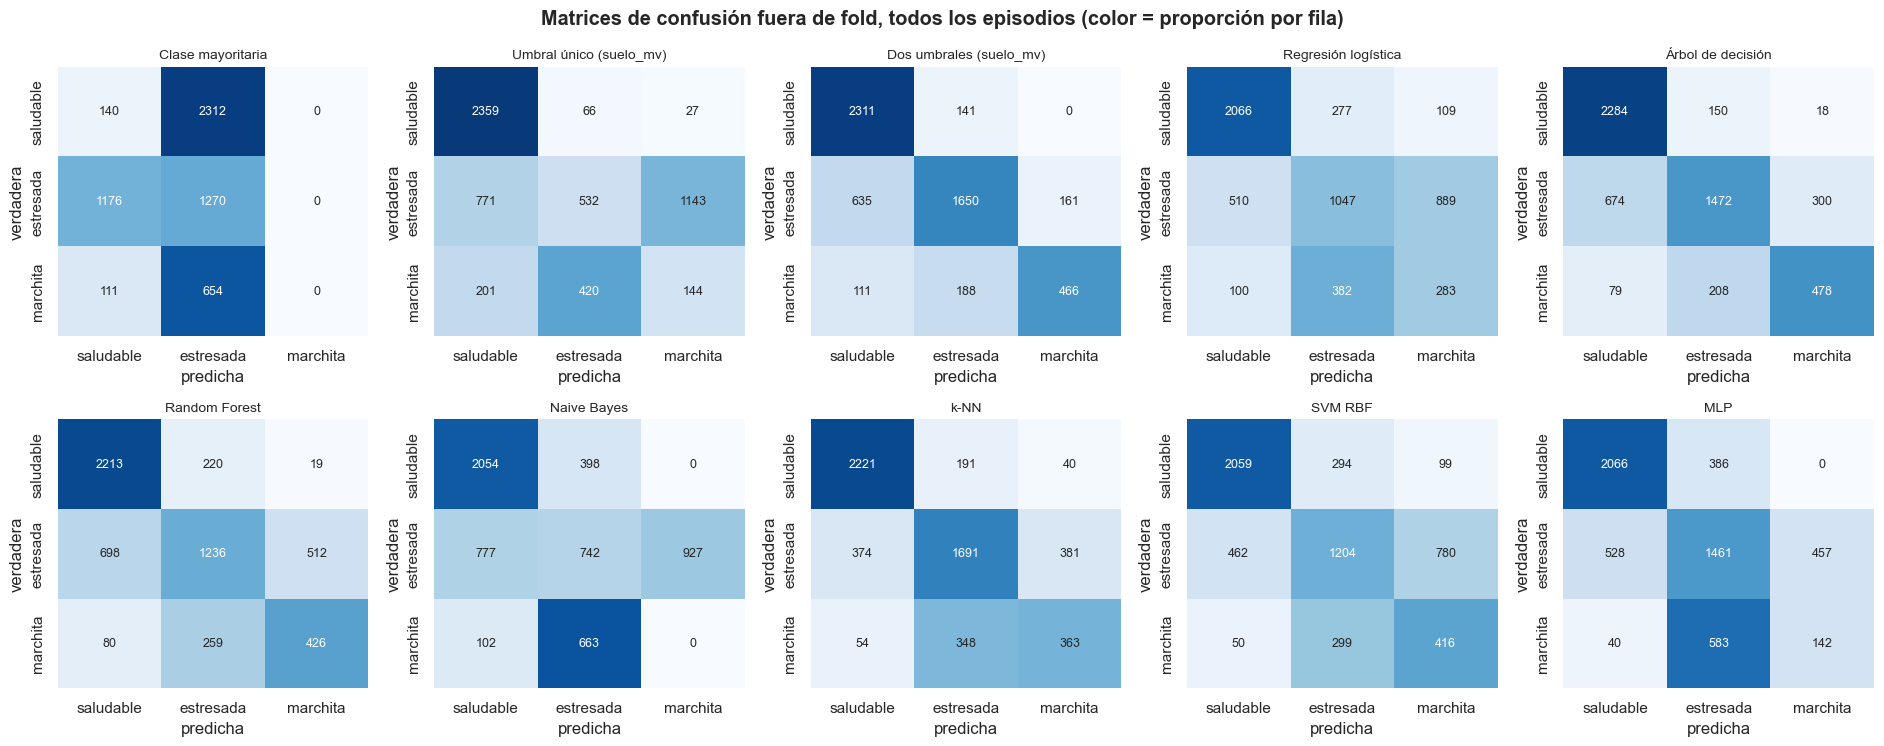

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(19, 7.6))
for ax, n in zip(axes.flat, orden):
    cm = confusion_matrix(y, resultados[n]["oof"], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(n, fontsize=10)
    ax.set_xlabel("predicha")
    ax.set_ylabel("verdadera")
fig.suptitle("Matrices de confusión fuera de fold, todos los episodios (color = proporción por fila)",
             fontweight="bold")
fig.tight_layout()
guardar(fig, "matrices_confusion_candidatos.png")
plt.show()

**Lectura de §4** (espacio restringido: suelo + al menos una ambiental del aire).

- **El mejor candidato es el árbol** (F1 macro sin dudosos 0,779 ± 0,054), seguido por k-NN (0,734) y Random Forest (0,692). Regresión logística, MLP y SVM quedan en 0,58–0,63 y Naive Bayes en 0,41.
- **Ninguno le gana al baseline de dos umbrales sobre `suelo_mv`** (0,822 ± 0,060). Sí todos menos Naive Bayes le ganan al umbral único (0,461) y a la clase mayoritaria (0,128).
- **Recall de marchita fuera de fold**: 0,73 el árbol, 0,71 los dos umbrales, 0,65 el RF. Naive Bayes no recupera ninguna.
- **Con todos los episodios** baja todo ~0,06–0,07: los dudosos 8, 9 y 14 siguen contradiciendo al sustrato.
- **Las búsquedas siguen eligiendo ambientales distintas en cada fold** (HR, T, VPD): ninguna se impone, coherente con un octubre de ambiente estable.

## 5. Costo en la ESP32, sensibilidad y selección

### 5.1 Costo

Para el costo se reentrena cada candidato con la misma búsqueda (partición interna por episodio) sobre **todos** los episodios: ese es el modelo que se exportaría. La estimación sale de `costo_esp32` (`modelos.py`): parámetros en `float` de 4 B en flash, RAM de trabajo durante la inferencia, operaciones por predicción y µs a 240 MHz (≈ 10 ciclos por operación y ≈ 1 µs por `expf`). Es un orden de magnitud para comparar; el tiempo del modelo elegido se mide en la placa (`t_us` del log `[INF]`). Todos se exportarían como tablas `static const` en flash: ninguno necesita memoria dinámica.

In [12]:
finales, costos, elegidos_full = {}, {}, {}
for nombre, (est, grilla) in MODELOS.items():
    if grilla:
        b = busqueda(est, grilla).fit(X, y, groups=g)
        finales[nombre] = b.best_estimator_
        elegidos_full[nombre] = b.best_params_
    else:
        finales[nombre] = clone(est).fit(X, y)
    costos[nombre] = costo_esp32(finales[nombre])

costo = pd.DataFrame(costos).T
costo["config"] = [describir(elegidos_full[n]) if n in elegidos_full else
                   f"[{nombre_subconjunto(finales[n].named_steps['sel'].columnas)}]"
                   for n in costo.index]
costo["flash_KB"] = costo.flash_B.astype(float) / 1024
display(costo[["config", "flash_B", "flash_KB", "ram_B", "ops", "exps", "t_us_est", "exportable"]])

,config,flash_B,flash_KB,ram_B,ops,exps,t_us_est,exportable
Clase mayoritaria,[suelo_mv+suelo_delta_1h+temp_c+hum_aire_pct+v...,4,0.004,0,0,0,0.000,sí (constante)
Umbral único (suelo_mv),[suelo],51,0.050,16,2,0,0.083,sí (if/else o tablas)
Dos umbrales (suelo_mv),[suelo],8,0.008,0,2,0,0.083,sí (dos if)
Regresión logística,[suelo+delta+temp] C=1.0,72,0.070,24,33,3,4.375,sí (producto matriz-vector)
Árbol de decisión,"[suelo+hr] max_depth=3, min_samples_leaf=20",231,0.226,16,6,0,0.250,sí (if/else o tablas)
Random Forest,"[suelo+hr] max_depth=5, min_samples_leaf=20",18510,18.076,28,390,0,16.250,sí (tablas)
Naive Bayes,[suelo+temp+hr],84,0.082,12,39,3,4.625,sí (fórmula cerrada)
k-NN,[suelo+delta+vpd] n_neighbors=5,73643,71.917,56,62299,0,"2,595.792","sí, pero guarda todo el train"
SVM RBF,[suelo+hr+vpd] C=1.0,58276,56.910,28,37862,2912,"4,489.583","sí, pero guarda los vectores soporte"
MLP,"[suelo+delta+temp] alpha=0.001, hidden_layer_s...",932,0.910,128,460,3,22.167,sí (capas densas)


### 5.2 Sensibilidad a los episodios dudosos y al episodio 13

El 19/10 hay dos observaciones con el botón a pocas horas de distancia y con la sonda casi en el mismo valor:

- el **ep. 12**: `marchita`, de noche, con ~1756 mV;
- el **ep. 13**: `estresada`, a la mañana siguiente, con ~1796 mV en la pulsación. La mediana del episodio es más alta porque después de la pulsación siguió 11–12 h propagado mientras el sustrato se secaba, hasta el riego.

Ninguna regla monótona sobre `suelo_mv` respeta las dos. El 13 no se marca dudoso (no hay motivo independiente de las métricas para hacerlo); se reporta la sensibilidad: las mismas métricas fuera de fold con todos, sin dudosos, sin el 13 y sin dudosos ni el 13. Con 24 episodios, sacar el 13 mueve las métricas menos de 0,01. **El criterio de selección de §5.3 no cambia**: usa "sin dudosos".

In [13]:
es_13 = (g == 13)
MASCARAS = {"todos": TODAS, "sin dudosos": sin_dud, "sin el 13": ~es_13, "sin dudosos ni el 13": sin_dud & ~es_13}
filas_s = {}
for n in orden:
    for nombre_m, m in MASCARAS.items():
        filas_s[(n, nombre_m)] = {met: fn(y[m], resultados[n]["oof"][m]) for met, fn in METRICAS_FN.items()}
sensibilidad = pd.DataFrame(filas_s).T
sensibilidad.index.names = ["modelo", "episodios"]
for met in METRICAS:
    print(f"\n{met} (fuera de fold)")
    display(sensibilidad[met].unstack("episodios").reindex(index=orden, columns=list(MASCARAS)))


exactitud_bal (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.192,0.165,0.182,0.151
Umbral único (suelo_mv),0.456,0.482,0.461,0.489
Dos umbrales (suelo_mv),0.742,0.818,0.740,0.818
Regresión logística,0.547,0.594,0.548,0.597
Árbol de decisión,0.719,0.792,0.719,0.794
Random Forest,0.655,0.718,0.653,0.718
Naive Bayes,0.380,0.401,0.366,0.384
k-NN,0.691,0.739,0.691,0.741
SVM RBF,0.625,0.665,0.622,0.662



f1_macro (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.151,0.128,0.141,0.116
Umbral único (suelo_mv),0.421,0.461,0.430,0.472
Dos umbrales (suelo_mv),0.751,0.822,0.754,0.827
Regresión logística,0.529,0.578,0.532,0.583
Árbol de decisión,0.711,0.779,0.717,0.788
Random Forest,0.634,0.692,0.636,0.697
Naive Bayes,0.371,0.408,0.355,0.391
k-NN,0.688,0.734,0.691,0.739
SVM RBF,0.597,0.628,0.597,0.628



recall_marchita (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.000,0.000,0.000,0.000
Umbral único (suelo_mv),0.188,0.220,0.188,0.220
Dos umbrales (suelo_mv),0.609,0.713,0.609,0.713
Regresión logística,0.370,0.433,0.370,0.433
Árbol de decisión,0.625,0.731,0.625,0.731
Random Forest,0.557,0.651,0.557,0.651
Naive Bayes,0.000,0.000,0.000,0.000
k-NN,0.475,0.555,0.475,0.555
SVM RBF,0.544,0.636,0.544,0.636


### 5.3 Criterio de selección

El contrato (§5.3) pide el mejor F1 macro dentro de 1 desvío del mejor, con flash < 32 KB, sin memoria dinámica y < 1 ms, desempatando por interpretabilidad. Las reglas se fijan antes de mirar quién gana:

1. **Restricciones duras**: flash < 32 KB, < 1 ms estimado, sin memoria dinámica.
2. **Rendimiento**: *puntaje* = F1 macro fuera de fold sobre los episodios no dudosos. Pasan los que quedan dentro de 1 desvío del mejor. El desvío sale del *bootstrap por episodio* del mejor.
3. **Desempate**: interpretabilidad (árbol / umbral = 1 … caja negra = 5), después puntaje.

Los baselines no son elegibles, pero se reporta si el elegido les gana.

In [14]:
LIMITE_FLASH_B, LIMITE_US = 32 * 1024, 1000
# Interpretabilidad para el desempate (1 = se lee entero en una hoja; 5 = caja negra).
INTERPRETABILIDAD = {"Clase mayoritaria": 1, "Umbral único (suelo_mv)": 1, "Dos umbrales (suelo_mv)": 1,
                     "Árbol de decisión": 1, "Regresión logística": 2, "Naive Bayes": 2,
                     "Random Forest": 3, "k-NN": 4, "SVM RBF": 5, "MLP": 5}


def puntaje_boot(pred):
    return np.array([f1m(y[idx], pred[idx]) for idx in REMUESTRAS["sin dudosos"]])


sel = pd.DataFrame({
    "puntaje": [resumen_cv.loc[n, ("sin dudosos", "f1_macro")] for n in orden],
    "puntaje_desvío": [resumen_cv.loc[n, ("sin dudosos", "f1_macro (desvío)")] for n in orden],
    "f1_todos": [resumen_cv.loc[n, ("todos", "f1_macro")] for n in orden],
    "exactitud_bal_sd": [resumen_cv.loc[n, ("sin dudosos", "exactitud_bal")] for n in orden],
    "recall_marchita_sd": [resumen_cv.loc[n, ("sin dudosos", "recall_marchita")] for n in orden],
    "flash_B": costo.flash_B.astype(int), "ram_B": costo.ram_B.astype(int),
    "t_us_est": costo.t_us_est.astype(float),
    "interpretabilidad": pd.Series(INTERPRETABILIDAD),
}, index=orden)
sel["baseline"] = pd.Series(ES_BASELINE)
sel["restricciones_ok"] = (sel.flash_B < LIMITE_FLASH_B) & (sel.t_us_est < LIMITE_US)   # todas sin malloc
pasan = sel[~sel.baseline & sel.restricciones_ok]
mejor = pasan.puntaje.idxmax()
desvio_mejor = pasan.loc[mejor, "puntaje_desvío"]
piso = pasan.loc[mejor, "puntaje"] - desvio_mejor
sel["puntaje_ok"] = sel.puntaje >= piso
sel["cumple"] = ~sel.baseline & sel.restricciones_ok & sel.puntaje_ok

print(f"1) restricciones: fuera por costo → {', '.join(sel[~sel.restricciones_ok].index) or 'ninguno'}")
print(f"2) mejor puntaje = {mejor} {pasan.loc[mejor, 'puntaje']:.3f}, desvío bootstrap por episodio "
      f"{desvio_mejor:.3f} ({df[sin_dud].episodio_id.nunique()} episodios, {N_BOOT} remuestras) → piso {piso:.3f}")
aptos = sel[sel.cumple].sort_values(["interpretabilidad", "puntaje"], ascending=[True, False])
print(f"   cumplen: {', '.join(aptos.index)}")
elegido = aptos.index[0]
print(f"3) ELEGIDO (interpretabilidad, después puntaje): {elegido}")
display(sel.drop(columns=["ram_B"]).sort_values("puntaje", ascending=False))

1) restricciones: fuera por costo → k-NN, SVM RBF
2) mejor puntaje = Árbol de decisión 0.779, desvío bootstrap por episodio 0.054 (20 episodios, 500 remuestras) → piso 0.725
   cumplen: Árbol de decisión
3) ELEGIDO (interpretabilidad, después puntaje): Árbol de decisión


,puntaje,puntaje_desvío,f1_todos,exactitud_bal_sd,recall_marchita_sd,flash_B,t_us_est,interpretabilidad,baseline,restricciones_ok,puntaje_ok,cumple
Dos umbrales (suelo_mv),0.822,0.060,0.751,0.818,0.713,8,0.083,1,True,True,True,False
Árbol de decisión,0.779,0.054,0.711,0.792,0.731,231,0.250,1,False,True,True,True
k-NN,0.734,0.058,0.688,0.739,0.555,73643,"2,595.792",4,False,False,True,False
Random Forest,0.692,0.052,0.634,0.718,0.651,18510,16.250,3,False,True,False,False
SVM RBF,0.628,0.072,0.597,0.665,0.636,58276,"4,489.583",5,False,False,False,False
MLP,0.590,0.074,0.540,0.589,0.217,932,22.167,5,False,True,False,False
Regresión logística,0.578,0.053,0.529,0.594,0.433,72,4.375,2,False,True,False,False
Umbral único (suelo_mv),0.461,0.091,0.421,0.482,0.220,51,0.083,1,True,True,False,False
Naive Bayes,0.408,0.072,0.371,0.401,0.000,84,4.625,2,False,True,False,False
Clase mayoritaria,0.128,0.061,0.151,0.165,0.000,4,0.000,1,True,True,False,False


figura: docs/entrega2/fig/rendimiento_vs_costo.png


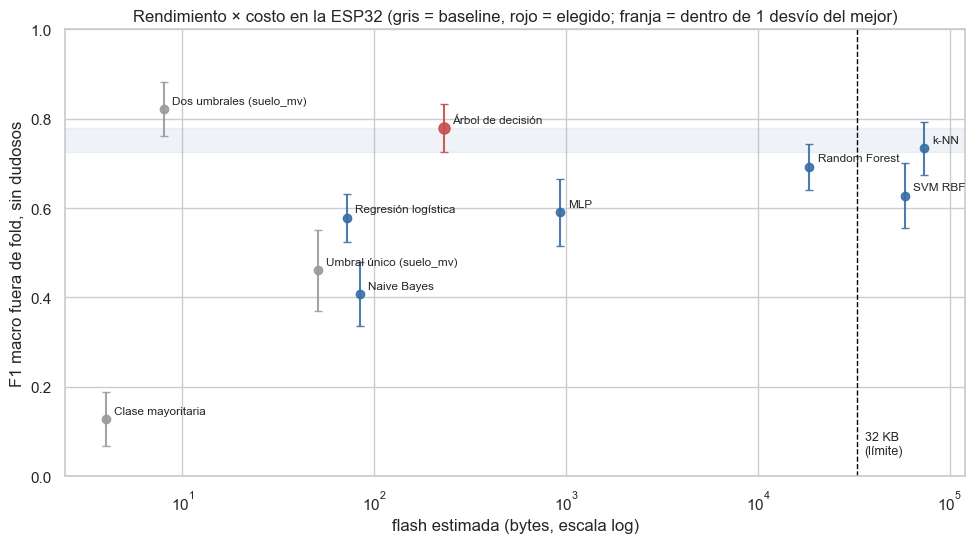

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.6))
for n, r in sel.iterrows():
    color = "#9a9a9a" if r.baseline else ("#c84b4b" if n == elegido else "#3a6ea5")
    ax.errorbar(max(r.flash_B, 4), r.puntaje, yerr=r.puntaje_desvío, fmt="o", color=color,
                ms=8 if n == elegido else 6, capsize=3, alpha=0.9)
    ax.annotate(n, (max(r.flash_B, 4), r.puntaje), textcoords="offset points", xytext=(6, 4), fontsize=8.5)
ax.axvline(LIMITE_FLASH_B, color="black", ls="--", lw=1)
ax.text(LIMITE_FLASH_B * 1.1, 0.05, "32 KB\n(límite)", fontsize=9)
ax.axhspan(piso, pasan.loc[mejor, "puntaje"], color="#3a6ea5", alpha=0.08)
ax.set_xscale("log")
ax.set(xlabel="flash estimada (bytes, escala log)", ylabel="F1 macro fuera de fold, sin dudosos", ylim=(0, 1),
       title="Rendimiento × costo en la ESP32 (gris = baseline, rojo = elegido; franja = dentro de 1 desvío del mejor)")
fig.tight_layout()
guardar(fig, "rendimiento_vs_costo.png")
plt.show()

### 5.4 El elegido contra el baseline de umbral

Comparación explícita con las reglas de umbral sobre `suelo_mv`: mismas predicciones fuera de fold (los modelos ven exactamente los mismos episodios de test) y la diferencia de puntaje en cada remuestra del bootstrap por episodio.

In [16]:
RIVALES = [elegido, "Dos umbrales (suelo_mv)", "Umbral único (suelo_mv)", "Clase mayoritaria"]
comp = sel.loc[RIVALES, ["puntaje", "puntaje_desvío", "f1_todos", "exactitud_bal_sd", "recall_marchita_sd", "flash_B"]]
display(comp)
for rival in RIVALES[1:3]:
    d = sel.loc[elegido, "puntaje"] - sel.loc[rival, "puntaje"]
    b_r = puntaje_boot(resultados[elegido]["oof"]) - puntaje_boot(resultados[rival]["oof"])
    print(f"puntaje {elegido} − {rival}: {d:+.3f}; en el bootstrap por episodio el elegido gana en "
          f"{(b_r > 0).mean():.0%} de las remuestras, empata en {(b_r == 0).mean():.0%}")

,puntaje,puntaje_desvío,f1_todos,exactitud_bal_sd,recall_marchita_sd,flash_B
Árbol de decisión,0.779,0.054,0.711,0.792,0.731,231
Dos umbrales (suelo_mv),0.822,0.060,0.751,0.818,0.713,8
Umbral único (suelo_mv),0.461,0.091,0.421,0.482,0.220,51
Clase mayoritaria,0.128,0.061,0.151,0.165,0.000,4


puntaje Árbol de decisión − Dos umbrales (suelo_mv): -0.043; en el bootstrap por episodio el elegido gana en 4% de las remuestras, empata en 0%


puntaje Árbol de decisión − Umbral único (suelo_mv): +0.318; en el bootstrap por episodio el elegido gana en 99% de las remuestras, empata en 0%


### 5.5 Configuración final y export

Dentro del tipo elegido se aplica la misma regla de parsimonia: entre las configuraciones de la búsqueda sobre todos los episodios con F1 macro interno dentro de 1 desvío de la mejor, la más simple (menos features, después menos profundidad). Tiene que coincidir con `CONFIG_FINAL` de `modelos.py`, que es lo que reentrena el exportador (`python -m plantaia_ml.exportar_c`), y su versión con la de `modelo_plantaia.h`. Si no coincide, la celda lo dice y hay que actualizar `CONFIG_FINAL`, re-exportar y volver a correr el notebook.

In [17]:
b_final = busqueda(*MODELOS[elegido]).fit(X, y, groups=g)
rk = pd.DataFrame(b_final.cv_results_).dropna(subset=["mean_test_score"])
rk["config"] = [describir(p) for p in rk.params]
rk["n_features"] = [len(p["sel__columnas"]) for p in rk.params]
rk["profundidad"] = [p.get("clf__max_depth", 0) for p in rk.params]
assert all(cumple_restriccion(p["sel__columnas"]) for p in rk.params), "restricción de diseño"
mejor_h = rk.loc[rk.mean_test_score.idxmax()]
piso_h = mejor_h.mean_test_score - mejor_h.std_test_score
rk["dentro_1_desvío"] = rk.mean_test_score >= piso_h
display(rk.sort_values("mean_test_score", ascending=False)
        [["config", "mean_test_score", "std_test_score", "n_features", "profundidad", "dentro_1_desvío"]]
        .head(10).reset_index(drop=True))
print(f"mejor configuración interna: {mejor_h.config} = {mejor_h.mean_test_score:.4f} ± {mejor_h.std_test_score:.4f}")

# Ranking de parsimonia: primero las configuraciones dentro de 1 desvío de la
# mejor, de la más simple a la más compleja (menos features, menos profundidad, mejor F1 interno);
# después las demás, por F1 interno. Se recorre en ese orden y se toma la primera que
#   (a) cumple las restricciones de la placa (flash < 32 KB, < 1 ms) y
#   (b) USA de verdad la ambiental: reemplazar sus features ambientales por la mediana
#       cambia la clase predicha en al menos MIN_CAMBIO_PCT % de las filas.
# (b) existe porque "tener" una ambiental en el subconjunto no alcanza: un bosque puede no cortar nunca
# por ella (o cortar en una zona donde no cambia la clase) y el LED seguiría dependiendo sólo de la sonda.
MEDIANA = np.median(X, axis=0)


def ambientales_de(mdl):
    return [int(c) for c in mdl.named_steps["sel"].columnas if int(c) in AMBIENTALES]


def pct_cambia(mdl, Xe, cols=None, ref=MEDIANA):
    # % de filas de Xe cuya clase predicha cambia al poner las columnas `cols` en `ref` (por defecto,
    # todas las ambientales que usa el modelo, en la mediana).
    cols = ambientales_de(mdl) if cols is None else list(cols)
    Xm = Xe.copy()
    Xm[:, cols] = ref[cols]
    return 100 * (mdl.predict(Xm) != mdl.predict(Xe)).mean()


ranking = pd.concat([
    rk[rk.dentro_1_desvío].sort_values(["n_features", "profundidad", "rank_test_score"], kind="stable"),
    rk[~rk.dentro_1_desvío].sort_values("rank_test_score", kind="stable")])
probadas, simple = [], None
for _, r in ranking.iterrows():
    mdl_c = clone(MODELOS[elegido][0]).set_params(**r.params).fit(X, y)
    cst = costo_esp32(mdl_c)
    pct = pct_cambia(mdl_c, X)
    ok_costo = cst["flash_B"] < LIMITE_FLASH_B and cst["t_us_est"] < LIMITE_US
    probadas.append({"config": r.config, "F1 interno": r.mean_test_score, "desvío": r.std_test_score,
                     "dentro_1_desvío": r.dentro_1_desvío, "flash_B": cst["flash_B"],
                     "% filas que cambian (ambiental → mediana)": pct,
                     "cumple": ok_costo and pct >= MIN_CAMBIO_PCT})
    if ok_costo and pct >= MIN_CAMBIO_PCT:
        simple = r
        break
tabla_probadas = pd.DataFrame(probadas)
print(f"configuraciones probadas en orden de parsimonia hasta la primera que usa la ambiental "
      f"(≥ {MIN_CAMBIO_PCT:g} % de las filas):")
display(tabla_probadas)
if simple is None:
    print("ninguna configuración del tipo elegido usa la ambiental: queda la mejor de la búsqueda")
    simple = mejor_h
print(f"configuración final: {simple.config} = {simple.mean_test_score:.4f} "
      f"({'dentro' if simple.dentro_1_desvío else 'FUERA'} de 1 desvío de la mejor)")
tipo_original = elegido
config_original = dict(simple.params)
print(f"→ criterio de §5.3 en el espacio restringido: {tipo_original} {describir(config_original)} "
      "(se revisa con la condición de seguridad en §5.6)")

,config,mean_test_score,std_test_score,n_features,profundidad,dentro_1_desvío
0,"[suelo+hr] max_depth=3, min_samples_leaf=20",0.710,0.110,2,3,True
1,"[suelo+hr] max_depth=2, min_samples_leaf=20",0.709,0.139,2,2,True
2,"[suelo+temp+hr] max_depth=2, min_samples_leaf=20",0.709,0.139,3,2,True
3,"[suelo+hr+vpd] max_depth=2, min_samples_leaf=20",0.709,0.139,3,2,True
4,"[suelo+temp] max_depth=2, min_samples_leaf=100",0.704,0.139,2,2,True
5,"[suelo+hr] max_depth=2, min_samples_leaf=100",0.704,0.139,2,2,True
6,"[suelo+hr+vpd] max_depth=2, min_samples_leaf=100",0.704,0.139,3,2,True
7,"[suelo+temp+vpd] max_depth=2, min_samples_leaf...",0.704,0.139,3,2,True
8,"[suelo+temp+hr] max_depth=2, min_samples_leaf=100",0.704,0.139,3,2,True
9,"[suelo+vpd] max_depth=2, min_samples_leaf=100",0.704,0.139,2,2,True


mejor configuración interna: [suelo+hr] max_depth=3, min_samples_leaf=20 = 0.7099 ± 0.1096
configuraciones probadas en orden de parsimonia hasta la primera que usa la ambiental (≥ 1 % de las filas):


,config,F1 interno,desvío,dentro_1_desvío,flash_B,% filas que cambian (ambiental → mediana),cumple
0,"[suelo+hr] max_depth=2, min_samples_leaf=20",0.709,0.139,True,111,0.000,False
1,"[suelo+temp] max_depth=2, min_samples_leaf=100",0.704,0.139,True,111,0.000,False
2,"[suelo+hr] max_depth=2, min_samples_leaf=100",0.704,0.139,True,111,0.000,False
3,"[suelo+vpd] max_depth=2, min_samples_leaf=100",0.704,0.139,True,111,0.000,False
4,"[suelo+temp] max_depth=2, min_samples_leaf=20",0.680,0.143,True,111,0.000,False
5,"[suelo+vpd] max_depth=2, min_samples_leaf=20",0.674,0.145,True,111,0.000,False
6,"[suelo+hr] max_depth=3, min_samples_leaf=20",0.710,0.110,True,231,1.148,True


configuración final: [suelo+hr] max_depth=3, min_samples_leaf=20 = 0.7099 (dentro de 1 desvío de la mejor)
→ criterio de §5.3 en el espacio restringido: Árbol de decisión [suelo+hr] max_depth=3, min_samples_leaf=20 (se revisa con la condición de seguridad en §5.6)


### 5.6 Condición de seguridad: no perder la marchita

El error caro es **no avisar marchita** (`docs/ENTREGA2.md` §5.1): un semáforo que no se pone en rojo ante la marchita observada de octubre (ep. 12) no sirve, aunque gane en F1. Por eso, además del criterio de §5.3, el modelo de la placa tiene que cumplir una **condición de seguridad** (`modelos.py`), sobre las predicciones fuera de fold sin dudosos:

- recall de `marchita` ≥ 0,9, **y**
- el ep. 12 con ≥ 50 % de sus filas bien.

**Cómo se elige.**

- **Grilla explícita** de configuraciones fijas (`modelos.configuraciones_seguridad`): suelo + cada ambiental y suelo + cada par de ambientales, con:
  - regresión logística (C 0,01 / 0,1 / 1);
  - árbol (prof. 2 / 3 / 4, hoja 100);
  - Random Forest chico de 30 árboles (prof. 3 / 5, hoja 20 / 100);
  - Naive Bayes.

  Son 66 configuraciones. Cada una se evalúa con los mismos 5 folds por episodio y se entrena además con todos los episodios.
- **Filtros, en orden:**
  1. costo (flash < 32 KB, < 1 ms);
  2. influencia ambiental ≥ 1 % (modelo entrenado con todo);
  3. condición de seguridad.
- **Entre las que pasan, el criterio de §5.3:** puntaje dentro de 1 desvío bootstrap del mejor; desempate por interpretabilidad, después menos features, después puntaje.
- **Chequeo extra:** con la sonda fuera del rango medido (900–1140 mV, más mojada que cualquier lectura) y T normal, el elegido no debe dar `marchita`.
- **Si ninguna configuración cumple, no se fuerza nada:** `CONFIG_FINAL` queda en la de §5.5 y se documenta.

In [18]:
from joblib import Parallel, delayed

folds_ext = list(particion_externa().split(X, y, g))
e12 = (g == EP_MARCHITA_OCTUBRE)
octubre = (df.ts >= "2026-10-01").to_numpy()
X_mojado = np.tile(np.median(X[octubre], axis=0), (241, 1)).astype(np.float32)
X_mojado[:, 0] = np.linspace(900, 1140, 241)      # más mojado que cualquier lectura (mín. ~1405 mV)
X_mojado[:, 1] = 0.0


def explorar(tipo, params):
    est = clone(MODELOS[tipo][0]).set_params(**params)
    oof_c = np.zeros(len(y), int)
    for tr, te in folds_ext:
        oof_c[te] = clone(est).fit(X[tr], y[tr]).predict(X[te])
    completo = clone(est).fit(X, y)
    cst = costo_esp32(completo)
    return {"tipo": tipo, "config": describir(params), "params": params,
            "n_features": len(params["sel__columnas"]),
            "puntaje": f1m(y[sin_dud], oof_c[sin_dud]), "f1_todos": f1m(y, oof_c),
            "recall_marchita_sd": recall_marchita(y[sin_dud], oof_c[sin_dud]),
            "ep12": (oof_c[e12] == 3).mean(),
            "exactitud_bal": balanced_accuracy_score(y, oof_c),
            "exactitud_bal_sd": balanced_accuracy_score(y[sin_dud], oof_c[sin_dud]),
            "pct_influencia": pct_cambia(completo, X),
            "pct_marchita_sonda_mojada": 100 * (completo.predict(X_mojado) == 3).mean(),
            "flash_B": cst["flash_B"], "t_us_est": cst["t_us_est"],
            "interpretabilidad": INTERPRETABILIDAD[tipo], "_oof": oof_c}


t0 = time.perf_counter()
filas_ex = Parallel(n_jobs=-1)(delayed(explorar)(t, p) for t, p in configuraciones_seguridad())
explor = pd.DataFrame(filas_ex)
print(f"{len(explor)} configuraciones exploradas en {time.perf_counter() - t0:.0f} s")
explor["costo_ok"] = (explor.flash_B < LIMITE_FLASH_B) & (explor.t_us_est < LIMITE_US)
explor["influencia_ok"] = explor.pct_influencia >= MIN_CAMBIO_PCT
explor["seguridad_ok"] = ((explor.recall_marchita_sd >= MIN_RECALL_MARCHITA)
                          & (explor.ep12 >= MIN_ACIERTO_EP12))
explor["pasa_filtros"] = explor.costo_ok & explor.influencia_ok & explor.seguridad_ok
embudo = explor.groupby("tipo").agg(configuraciones=("config", "size"), costo=("costo_ok", "sum"),
                                    seguridad=("seguridad_ok", "sum"),
                                    **{"costo + influencia": ("influencia_ok", lambda s: int((s & explor.loc[s.index, "costo_ok"]).sum()))},
                                    **{"costo + influencia + seguridad": ("pasa_filtros", "sum")},
                                    max_recall_marchita=("recall_marchita_sd", "max"), max_ep12=("ep12", "max"))
print("Cuántas configuraciones de cada tipo pasan cada filtro:")
display(embudo)
COLS_EX = ["tipo", "config", "puntaje", "f1_todos", "recall_marchita_sd", "ep12", "exactitud_bal_sd",
           "pct_influencia", "pct_marchita_sonda_mojada", "flash_B", "costo_ok", "influencia_ok", "seguridad_ok"]
print("La mejor configuración (por puntaje) de cada tipo, pase o no los filtros:")
display(explor.sort_values("puntaje", ascending=False).groupby("tipo").head(1)[COLS_EX].set_index(["tipo", "config"]))

66 configuraciones exploradas en 1 s
Cuántas configuraciones de cada tipo pasan cada filtro:


,configuraciones,costo,seguridad,costo + influencia,costo + influencia + seguridad,max_recall_marchita,max_ep12
tipo,,,,,,,
Naive Bayes,6,6,0,6,0,0.156,0.000
Random Forest,24,24,0,23,0,0.760,0.000
Regresión logística,18,18,0,18,0,0.719,0.000
Árbol de decisión,18,18,0,9,0,0.731,0.000


La mejor configuración (por puntaje) de cada tipo, pase o no los filtros:


,,puntaje,f1_todos,recall_marchita_sd,ep12,exactitud_bal_sd,pct_influencia,pct_marchita_sonda_mojada,flash_B,costo_ok,influencia_ok,seguridad_ok
tipo,config,,,,,,,,,,,
Árbol de decisión,"[suelo+vpd] max_depth=2, min_samples_leaf=100",0.773,0.708,0.731,0.000,0.788,0.000,0.000,111,True,False,False
Random Forest,"[suelo+hr] max_depth=3, min_samples_leaf=100",0.733,0.672,0.751,0.000,0.762,0.812,0.000,5340,True,False,False
Regresión logística,[suelo+vpd] C=0.1,0.662,0.607,0.717,0.000,0.706,2.719,0.000,52,True,True,False
Naive Bayes,[suelo+temp+vpd],0.599,0.546,0.156,0.000,0.600,5.810,92.946,84,True,True,False


In [19]:
# Criterio de §5.3 entre las configuraciones que pasan costo, influencia y seguridad.
aptas = explor[explor.pasa_filtros].copy()
if aptas.empty:
    print("NINGUNA configuración cumple costo + influencia ambiental + seguridad: CONFIG_FINAL queda en "
          f"el criterio de §5.5 ({tipo_original} {describir(config_original)}).")
    final_tipo, final_params = tipo_original, config_original
    desvio_s = np.nan
else:
    mejor_s = aptas.puntaje.idxmax()
    desvio_s = puntaje_boot(explor.loc[mejor_s, "_oof"]).std(ddof=0)
    piso_s = aptas.loc[mejor_s, "puntaje"] - desvio_s
    aptas["puntaje_ok"] = aptas.puntaje >= piso_s
    print(f"pasan costo + influencia + seguridad: {len(aptas)} configuraciones "
          f"({', '.join(f'{k}: {v}' for k, v in aptas.tipo.value_counts().items())})")
    print(f"mejor puntaje = {aptas.loc[mejor_s, 'tipo']} {aptas.loc[mejor_s, 'config']} "
          f"{aptas.loc[mejor_s, 'puntaje']:.3f}, desvío bootstrap por episodio {desvio_s:.3f} "
          f"→ piso {piso_s:.3f}; pasan {int(aptas.puntaje_ok.sum())}")
    finalistas = (aptas[aptas.puntaje_ok]
                  .sort_values(["interpretabilidad", "n_features", "puntaje"], ascending=[True, True, False]))
    display(finalistas[COLS_EX + ["interpretabilidad"]].set_index(["tipo", "config"]))
    final_tipo, final_params = finalistas.iloc[0].tipo, dict(finalistas.iloc[0].params)
    print(f"ELEGIDO con la condición de seguridad (interpretabilidad, menos features, puntaje): "
          f"{final_tipo} {describir(final_params)}")
tabla_candidatos_seg = (explor.sort_values(["pasa_filtros", "puntaje"], ascending=False)[COLS_EX]
                        .set_index(["tipo", "config"]))

NINGUNA configuración cumple costo + influencia ambiental + seguridad: CONFIG_FINAL queda en el criterio de §5.5 (Árbol de decisión [suelo+hr] max_depth=3, min_samples_leaf=20).


In [20]:
# Modelo de la placa: tiene que coincidir con CONFIG_FINAL y con el header exportado.
elegido = final_tipo
print("CONFIG_FINAL en modelos.py:", CONFIG_FINAL["tipo"], describir(CONFIG_FINAL["params"]))
coincide = CONFIG_FINAL["tipo"] == final_tipo and set(final_params) == set(CONFIG_FINAL["params"]) and all(
    (tuple(final_params[k]) if k == "sel__columnas" else final_params[k]) == v for k, v in CONFIG_FINAL["params"].items())
print("→ coincide con CONFIG_FINAL" if coincide else
      "→ ¡NO COINCIDE! Actualizar CONFIG_FINAL en modelos.py, re-exportar y re-ejecutar.")

modelo = modelo_final().fit(X, y)
assert cumple_restriccion(modelo.named_steps["sel"].columnas), "el modelo de la placa no usa ninguna ambiental"
version = version_modelo(modelo)
en_header = next(l.split('"')[1] for l in RUTA_MODELO.read_text().splitlines()
                 if "PLANTAIA_MODELO_VERSION" in l and "#define" in l)
print(f"versión del modelo (CONFIG_FINAL reentrenado ahora): {version} · en modelo_plantaia.h: {en_header}")
print("→ el header está al día" if version == en_header else
      "→ ¡HEADER DESACTUALIZADO! correr: cd ml && python -m plantaia_ml.exportar_c")

# Sonda fuera del rango medido (más mojada que cualquier lectura) con T normal: no debe dar marchita.
p_moj = modelo.predict(X_mojado)
print(f"sonda 900–1140 mV, resto en la mediana de octubre (T = {X_mojado[0, 2]:.1f} °C): "
      + ", ".join(f"{CLASES[k - 1]} {100 * (p_moj == k).mean():.0f} %" for k in CODIGOS))
X_seca = X_mojado.copy()
X_seca[:, 0] = np.linspace(3000, 3124, 241)
print("sonda 3000–3124 mV (más seca que todo lo medido salvo septiembre):",
      ", ".join(f"{CLASES[k - 1]} {100 * (modelo.predict(X_seca) == k).mean():.0f} %" for k in CODIGOS))

CONFIG_FINAL en modelos.py: Árbol de decisión [suelo+hr] max_depth=3, min_samples_leaf=20
→ coincide con CONFIG_FINAL
versión del modelo (CONFIG_FINAL reentrenado ahora): arbol-p3-f03-ee3419 · en modelo_plantaia.h: arbol-p3-f03-ee3419
→ el header está al día
sonda 900–1140 mV, resto en la mediana de octubre (T = 20.1 °C): saludable 0 %, estresada 100 %, marchita 0 %
sonda 3000–3124 mV (más seca que todo lo medido salvo septiembre): saludable 0 %, estresada 0 %, marchita 100 %


**El modelo final y el del criterio de §5.5, lado a lado.** Se agrega el % de filas predichas `marchita` en la ventana post-arranque que el filtrado descarta. Ahí la sonda baja rápido por el transitorio y `suelo_delta_1h` mide deriva, no secado.

In [21]:
todo_pb = serie_maceta01(filtrado=False)
todo_pb = todo_pb[todo_pb.valido & todo_pb.post_boot]
Xpb = matriz_X(todo_pb)
filas_cfg = {}
pares = [("CONFIG_FINAL", CONFIG_FINAL["tipo"], CONFIG_FINAL["params"]),
         ("criterio de §5.5 (sin seguridad)", tipo_original, config_original)]
for etiqueta, tipo_c, params in pares:
    est_c = clone(MODELOS[tipo_c][0]).set_params(**params)
    r_c = evaluar(est_c, {})
    completo = clone(est_c).fit(X, y)
    filas_cfg[f"{etiqueta}: {tipo_c} {describir(params)}"] = {
        "F1 macro fuera de fold, sin dudosos": f1m(y[sin_dud], r_c["oof"][sin_dud]),
        "F1 macro fuera de fold, todos": f1m(y, r_c["oof"]),
        "exactitud bal. fuera de fold, todos": balanced_accuracy_score(y, r_c["oof"]),
        "% filas predichas marchita (modelo con todo)": 100 * (completo.predict(X) == 3).mean(),
        "% marchita en la ventana post-arranque descartada": 100 * (completo.predict(Xpb) == 3).mean()
        if len(Xpb) else np.nan,
    }
print(f"% de marchita en las filas: {100 * (y == 3).mean():.1f} % · "
      f"filas en la ventana post-arranque: {len(Xpb)}")
display(pd.DataFrame(filas_cfg).T)

fija = evaluar(modelo_final(), {})
print("\nConfiguración final fija (sin búsqueda) vs. búsqueda anidada del tipo:")
display(tabla_metricas({"config. final fija": fija, f"{CONFIG_FINAL['tipo']} (búsqueda anidada)":
                        resultados[CONFIG_FINAL["tipo"]]}))
print("costo:", costo_esp32(modelo))
print()
# Barrido de suelo_mv con el resto de las features en la mediana y delta = 0: es un corte
# del modelo con el ambiente "típico". Cómo se mueve con el ambiente está en §5.7.
xs = np.arange(900, 3200.25, 0.25)
Xgrid = np.tile(MEDIANA, (len(xs), 1)).astype(np.float32)
Xgrid[:, 0] = xs
Xgrid[:, 1] = 0.0
pred_grid = modelo.predict(Xgrid)
proba_grid = modelo.predict_proba(Xgrid)
cambios = np.flatnonzero(np.diff(pred_grid)) + 1
umbrales_final = [float(xs[i]) for i in cambios]
tramos = np.split(np.arange(len(xs)), cambios)
print("features que usa:", [FEATURES[c] for c in modelo.named_steps["sel"].columnas])
print("clase predicha por tramo de suelo_mv (mV), con las ambientales en la mediana:")
for t in tramos:
    print(f"  {xs[t[0]]:7.2f} – {xs[t[-1]]:7.2f}  → {CLASES[pred_grid[t[0]] - 1]}")
if hasattr(modelo.named_steps["clf"], "tree_"):
    print(export_text(modelo.named_steps["clf"],
                      feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas], decimals=1))

% de marchita en las filas: 13.5 % · filas en la ventana post-arranque: 196


,"F1 macro fuera de fold, sin dudosos","F1 macro fuera de fold, todos","exactitud bal. fuera de fold, todos",% filas predichas marchita (modelo con todo),% marchita en la ventana post-arranque descartada
"CONFIG_FINAL: Árbol de decisión [suelo+hr] max_depth=3, min_samples_leaf=20",0.711,0.651,0.669,10.984,12.245
"criterio de §5.5 (sin seguridad): Árbol de decisión [suelo+hr] max_depth=3, min_samples_leaf=20",0.711,0.651,0.669,10.984,12.245



Configuración final fija (sin búsqueda) vs. búsqueda anidada del tipo:


todos                                   sin dudosos                                      todos sin dudosos
                                      exactitud_bal       f1_macro recall_marchita  exactitud_bal       f1_macro recall_marchita roc_auc_ovr roc_auc_ovr
config. final fija                    0.669 ± 0.071  0.651 ± 0.064   0.590 ± 0.165  0.737 ± 0.062  0.711 ± 0.053   0.690 ± 0.148       0.741       0.817
Árbol de decisión (búsqueda anidada)  0.719 ± 0.074  0.711 ± 0.068   0.625 ± 0.176  0.792 ± 0.064  0.779 ± 0.054   0.731 ± 0.158       0.771       0.834

costo: {'flash_B': 231, 'ram_B': 16, 'ops': 6, 'exps': 0, 't_us_est': 0.25, 'exportable': 'sí (if/else o tablas)'}

features que usa: ['suelo_mv', 'hum_aire_pct']
clase predicha por tramo de suelo_mv (mV), con las ambientales en la mediana:
   900.00 – 1445.75  → estresada
  1446.00 – 1716.50  → saludable
  1716.75 – 1936.50  → estresada
  1936.75 – 3200.00  → marchita
|--- suelo_mv <= 1743.5
|   |--- suelo_mv <= 1488.2
|   |   |--- suelo_mv <= 1445.8
|   |   |   |--- class: 2
|   |   |--- suelo_mv >  1445.8
|   |   |   |--- class: 1
|   |--- suelo_mv >  1488.2
|   |   |--- suelo_mv <= 1716.5
|   |   |   |--- class: 1
|   |   |--- suelo_mv >  1716.5
|   |   |   |--- class: 2
|--- suelo_mv >  1743.5
|   |--- suelo_mv <= 1936.5
|   |   |--- hum_aire_pct <= 47.8
|   |   |   |--- class: 2
|   |   |--- hum_aire_pct >  47.8
|   |   |   |--- class: 2
|   |--- suelo_mv >  1936.5
|   |   |--- hum_aire_pct <= 43.5
|   |   |   |--- class: 2
|   |   |--- hum_aire_pct >  43.5
|   |   |   |--- class

figura: docs/entrega2/fig/arbol_final.png


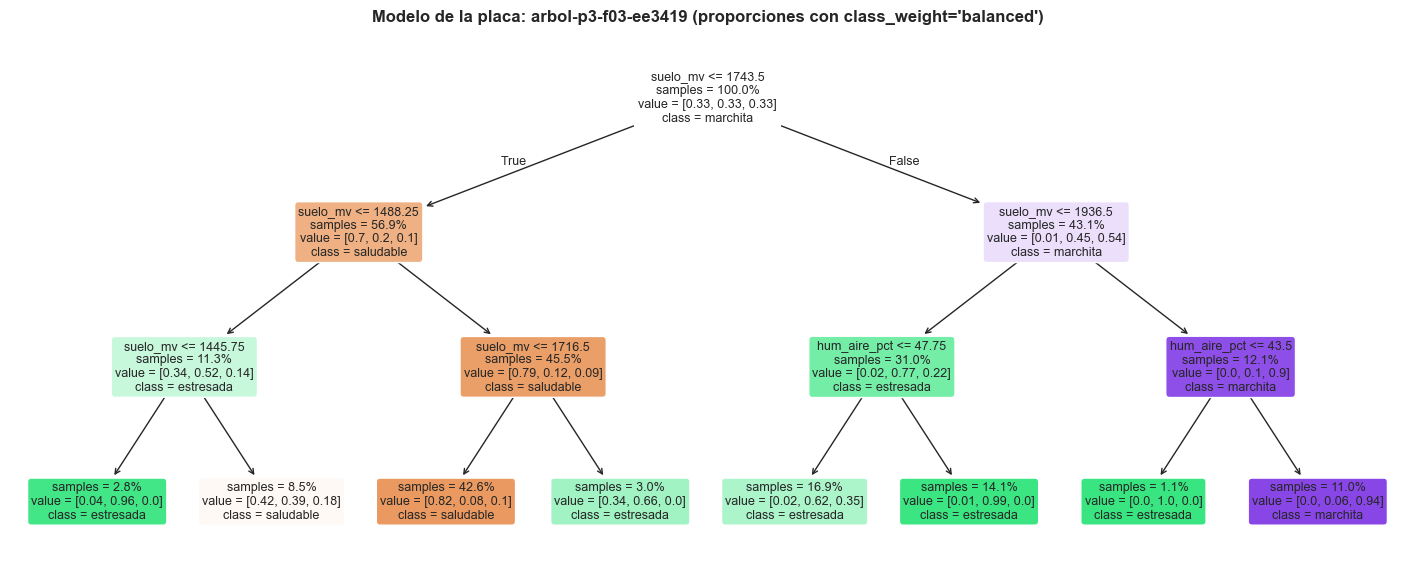

figura: docs/entrega2/fig/modelo_final_suelo_mv.png


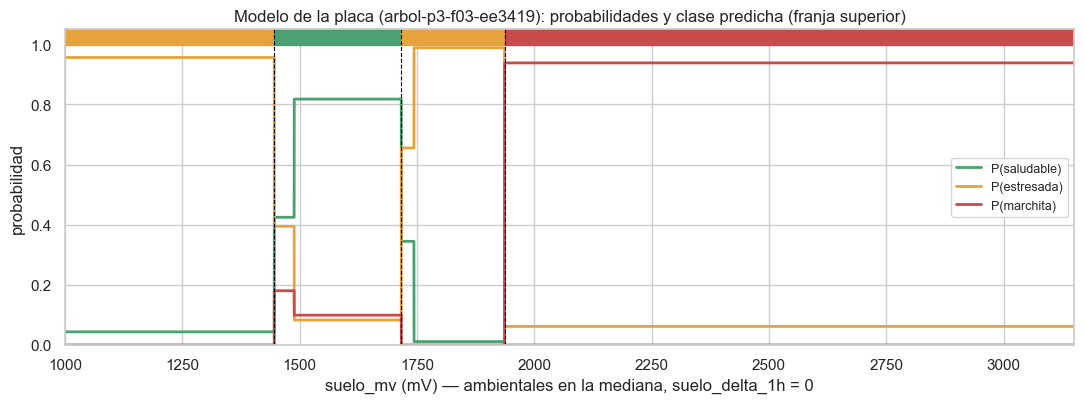

figura: docs/entrega2/fig/matriz_confusion_final.png


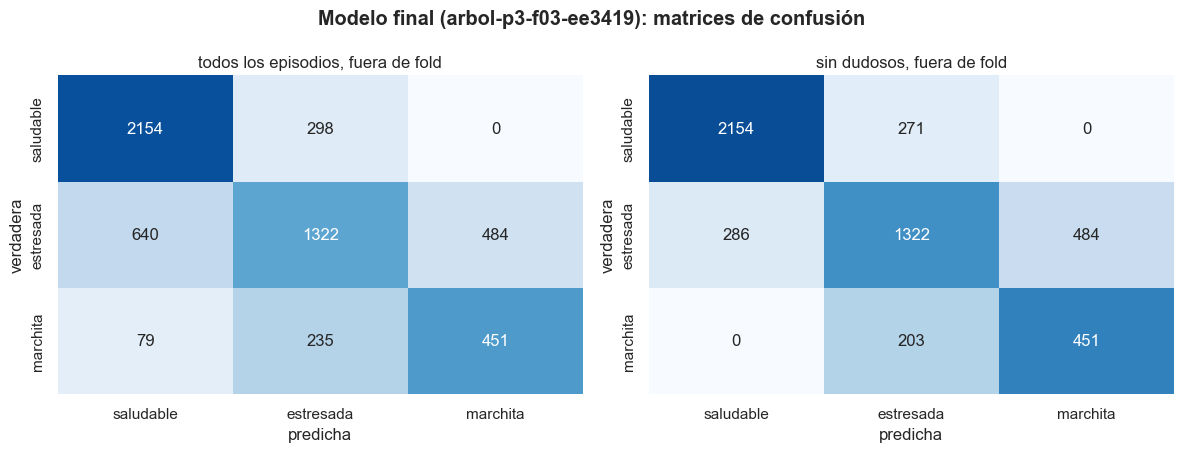

In [22]:
clf_final = modelo.named_steps["clf"]
if hasattr(clf_final, "tree_"):
    prof = clf_final.get_depth()
    fig, ax = plt.subplots(figsize=(11, 5.2) if prof <= 2 else (18, 7))
    plot_tree(clf_final, feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas],
              class_names=CLASES, filled=True, impurity=False, proportion=True, rounded=True,
              precision=2, fontsize=10 if prof <= 2 else 9, ax=ax)
    ax.set_title(f"Modelo de la placa: {version} (proporciones con class_weight='balanced')", fontweight="bold")
    guardar(fig, "arbol_final.png")
    plt.show()
else:
    (FIGURAS / "arbol_final.png").unlink(missing_ok=True)   # de una ejecución anterior con un árbol

# El modelo final como función de suelo_mv: probabilidad de cada clase y clase predicha.
fig, ax = plt.subplots(figsize=(11, 4.2))
for k, c in enumerate(CLASES):
    ax.plot(xs, proba_grid[:, k], color=COLORES[c], lw=2, label=f"P({c})")
for t in tramos:
    ax.axvspan(xs[t[0]], xs[t[-1]], ymin=0.95, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
for u in umbrales_final:
    ax.axvline(u, color="black", ls="--", lw=0.8)
ax.set(xlabel="suelo_mv (mV) — ambientales en la mediana, suelo_delta_1h = 0",
       ylabel="probabilidad", ylim=(0, 1.05), xlim=(1000, 3150),
       title=f"Modelo de la placa ({version}): probabilidades y clase predicha (franja superior)")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
guardar(fig, "modelo_final_suelo_mv.png")
plt.show()

oof_fija = fija["oof"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (titulo, m) in zip(axes, [("todos los episodios, fuera de fold", TODAS),
                                  ("sin dudosos, fuera de fold", sin_dud)]):
    cm = confusion_matrix(y[m], oof_fija[m], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", vmin=0,
                vmax=1, xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax)
    ax.set(title=titulo, xlabel="predicha", ylabel="verdadera")
fig.suptitle(f"Modelo final ({version}): matrices de confusión", fontweight="bold")
fig.tight_layout()
guardar(fig, "matriz_confusion_final.png")
plt.show()

**Lectura de la selección.**

**1) Criterio de §5.3** (espacio sin luz):

- **Costo.** Quedan afuera k-NN (72 KB, ~2,6 ms) y SVM RBF (57 KB, ~4,5 ms).
- **Puntaje.** El mejor es el árbol (0,779, desvío bootstrap 0,054) → piso 0,725. Sólo el árbol queda dentro: el RF (0,692) y el resto quedan abajo.
- **Configuración.** Dentro del árbol, las de profundidad 2 con una ambiental **no la usan** (0 % de filas cambian si la ambiental va a la mediana). La primera en orden de parsimonia que sí la usa es `suelo+hr`, profundidad 3, hoja 20 (F1 interno 0,710 ± 0,110, la mejor de la búsqueda): 1,1 % de las filas cambian de clase sin la HR, apenas por encima de la compuerta del 1 %.
- **Contra los umbrales.** El árbol de la búsqueda pierde contra los dos umbrales (−0,043) y gana sólo en el 4 % de las remuestras: **el baseline es mejor**, no un empate. Contra el umbral único gana en el 99 %.

**2) Condición de seguridad** (§5.6): **ninguna de las 66 configuraciones la cumple.**

- El recall de marchita sin dudosos llega a 0,76 (RF), pero **el ep. 12 no lo acierta ninguna** (0 %): con 1758 mV cae en la zona `estresada` de la escala de octubre que fijan los ciclos del 03/10 al 18/10 (1720–1940 mV).
- La condición se fijó con un solo episodio de marchita en octubre; ahora hay tres más (eps. 18, 22, 26). No se relaja después de ver los resultados: por la regla de §5.6 queda la configuración de §5.5.

**Elegido: árbol de decisión de profundidad 3 con `suelo_mv` y `hum_aire_pct`** (`arbol-p3-f03-ee3419`). Leído como reglas (las hojas iguales se juntan):

| condición | clase |
|---|---|
| `suelo_mv` ≤ 1445,75 mV | estresada |
| 1445,75 < `suelo_mv` ≤ 1716,5 mV | saludable |
| 1716,5 < `suelo_mv` ≤ 1936,5 mV | estresada |
| `suelo_mv` > 1936,5 mV y `hum_aire_pct` ≤ 43,5 % | estresada |
| `suelo_mv` > 1936,5 mV y `hum_aire_pct` > 43,5 % | marchita |

- **Costo.** 15 nodos, 231 B de flash, a lo sumo 3 comparaciones por predicción. El firmware completo usa el 73,4 % de la flash.
- **La rama "muy mojado → estresada"** (≤ 1446 mV) sale sobre todo del ep. 14 (dudoso, ~1445 mV) y de las recuperaciones post-riego. Con la sonda fuera del rango medido (900–1140 mV) da `estresada` al 100 %: una planta recién regada con la sonda muy húmeda prendería el amarillo.
- **Sonda seca** (3000–3124 mV): `marchita` al 100 %.
- **Fuera de fold** (configuración fija): F1 macro 0,711 ± 0,053 sin dudosos (0,651 con todos), exactitud balanceada 0,737 / 0,669, recall de marchita 0,69 / 0,59, ROC-AUC OvR 0,82 / 0,74.

### 5.7 Restricción de diseño: el modelo debe usar variables ambientales

**La decisión.** Un modelo sólo con `suelo_mv` deja al LED respondiendo únicamente a la sonda. Se decidió que eso está mal como producto:

- La sonda es **resistiva y deriva**: la misma marchita marcaba ~2830 mV en septiembre y ~1758 mV en octubre.
- La maceta tiene sensores de ambiente que el semáforo ignoraría.

Por eso todo candidato con selección de features se busca dentro de **`suelo_mv` + al menos una ambiental** (`temp_c`, `hum_aire_pct`, `vpd_kpa`; `suelo_delta_1h` no cuenta). Es una **restricción de producto, no un resultado de las métricas**. La exclusión de la luz, en cambio, **se decidió después de ver resultados** (§6.3). La compuerta de influencia (≥ 1 % de filas que cambian de clase, §5.5) y la condición de seguridad (§5.6) también son decisiones de producto: hacen que el elegido no sea necesariamente el de mejor F1, y sus números quedan algo optimistas.

**Qué cuesta la restricción.** Se compara, con los mismos folds, contra un Random Forest de la misma receta con sólo `suelo_mv`, contra el modelo del criterio de §5.5 y contra los dos umbrales.

**Cómo se verifica que la ambiental influye:**

1. importancia por permutación;
2. % de filas cuya clase cambia si la ambiental va a su mediana, y en qué episodios y hacia dónde;
3. barrido con `suelo_mv` fijo en valores típicos de octubre y la ambiental en su rango medido;
4. si la ambiental actúa como proxy de la hora (la clase está atada al horario del observador, §6.3).

In [23]:
# Mismo RF (30 árboles, prof. 5, hoja 20) sin la restricción: sólo suelo_mv. Mismos folds.
SOLO_SUELO = {"sel__columnas": (0,), "clf__max_depth": 5, "clf__min_samples_leaf": 20}
est_ss = clone(MODELOS["Random Forest"][0]).set_params(**SOLO_SUELO)
mdl_ss = clone(est_ss).fit(X, y)
version_ss = version_modelo(mdl_ss)
fija_ss = evaluar(est_ss, {})
est_or = clone(MODELOS[tipo_original][0]).set_params(**config_original)
mdl_or = clone(est_or).fit(X, y)
version_or = version_modelo(mdl_or) if not isinstance(mdl_or.named_steps["clf"], UmbralesOrdenados) else "umbrales"
fija_or = evaluar(est_or, {})

DU = "Dos umbrales (suelo_mv)"
k_ss, k_or, k_nv = f"sólo suelo ({version_ss})", f"criterio §5.5 ({version_or})", f"final ({version})"
COMPARADOS = {k_ss: fija_ss["oof"], k_or: fija_or["oof"], k_nv: fija["oof"], "dos umbrales (baseline)": resultados[DU]["oof"]}
filas_cmp = []
for nombre_m, pred in COMPARADOS.items():
    for mk, m in MASCARAS.items():
        filas_cmp.append({"modelo": nombre_m, "episodios": mk,
                          **{met: fn(y[m], pred[m]) for met, fn in METRICAS_FN.items()}})
comparacion = pd.DataFrame(filas_cmp).set_index(["modelo", "episodios"])
for met in METRICAS:
    print(f"\n{met} (fuera de fold)")
    display(comparacion[met].unstack("episodios")[list(MASCARAS)])

resumen_cmp = pd.DataFrame({
    n: {"puntaje (F1 sin dudosos)": f1m(y[sin_dud], COMPARADOS[n][sin_dud]),
        "desvío bootstrap": puntaje_boot(COMPARADOS[n]).std(),
        "flash estimada (costo_esp32, float, B)": costo_esp32(m_f)["flash_B"],
        "flash del header exportado (B)": bytes_parametros_c(m_f) if not isinstance(
            m_f.named_steps["clf"], UmbralesOrdenados) else np.nan,   # baseline: no se exporta
        "recall marchita sin dudosos": recall_marchita(y[sin_dud], COMPARADOS[n][sin_dud]),
        "ep. 12": (COMPARADOS[n][e12] == 3).mean(),
        "features": ", ".join(FEATURES[c] for c in m_f.named_steps["sel"].columnas)}
    for n, m_f in [(k_ss, mdl_ss), (k_or, mdl_or), (k_nv, modelo), ("dos umbrales (baseline)", finales[DU])]}).T
display(resumen_cmp)
b_dif = puntaje_boot(COMPARADOS[k_nv]) - puntaje_boot(COMPARADOS[k_ss])
print(f"puntaje final − sólo suelo: {f1m(y[sin_dud], COMPARADOS[k_nv][sin_dud]) - f1m(y[sin_dud], COMPARADOS[k_ss][sin_dud]):+.3f} "
      f"(bootstrap por episodio: el final gana en {(b_dif > 0).mean():.0%} de las remuestras, empata en "
      f"{(b_dif == 0).mean():.0%}; desvío de la diferencia {b_dif.std(ddof=0):.3f})")


exactitud_bal (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
criterio §5.5 (arbol-p3-f03-ee3419),0.669,0.737,0.668,0.737
dos umbrales (baseline),0.742,0.818,0.740,0.818
final (arbol-p3-f03-ee3419),0.669,0.737,0.668,0.737
sólo suelo (rf-f0-532763),0.628,0.687,0.629,0.691



f1_macro (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
criterio §5.5 (arbol-p3-f03-ee3419),0.651,0.711,0.655,0.716
dos umbrales (baseline),0.751,0.822,0.754,0.827
final (arbol-p3-f03-ee3419),0.651,0.711,0.655,0.716
sólo suelo (rf-f0-532763),0.621,0.678,0.627,0.686



recall_marchita (fuera de fold)


episodios,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
criterio §5.5 (arbol-p3-f03-ee3419),0.590,0.690,0.590,0.690
dos umbrales (baseline),0.609,0.713,0.609,0.713
final (arbol-p3-f03-ee3419),0.590,0.690,0.590,0.690
sólo suelo (rf-f0-532763),0.442,0.517,0.442,0.517


,puntaje (F1 sin dudosos),desvío bootstrap,"flash estimada (costo_esp32, float, B)",flash del header exportado (B),recall marchita sin dudosos,ep. 12,features
sólo suelo (rf-f0-532763),0.678,0.063,24000,24060,0.517,0.000,suelo_mv
criterio §5.5 (arbol-p3-f03-ee3419),0.711,0.053,231,231,0.690,0.000,"suelo_mv, hum_aire_pct"
final (arbol-p3-f03-ee3419),0.711,0.053,231,231,0.690,0.000,"suelo_mv, hum_aire_pct"
dos umbrales (baseline),0.822,0.060,8,NaN,0.713,0.000,suelo_mv


puntaje final − sólo suelo: +0.033 (bootstrap por episodio: el final gana en 74% de las remuestras, empata en 0%; desvío de la diferencia 0.054)


In [24]:
# Verificación de que las ambientales influyen en el modelo de la placa (entrenado con todos los episodios).
cols_amb = ambientales_de(modelo)
print("features del modelo final:", [FEATURES[c] for c in modelo.named_steps["sel"].columnas],
      "· ambientales:", [FEATURES[c] for c in cols_amb])
N_PERM = 30
rng_p = np.random.default_rng(0)
filas_pi = []
base_p = modelo.predict(X)
base_ba = balanced_accuracy_score(y, base_p)
for c in modelo.named_steps["sel"].columnas:
    caidas, cambios_p = [], []
    for _ in range(N_PERM):
        Xp = X.copy()
        Xp[:, c] = rng_p.permutation(Xp[:, c])
        pp = modelo.predict(Xp)
        caidas.append(base_ba - balanced_accuracy_score(y, pp))
        cambios_p.append(100 * (pp != base_p).mean())
    filas_pi.append({"feature": FEATURES[c], "caída exactitud bal. (media)": np.mean(caidas),
                     "desvío": np.std(caidas), "% predicciones que cambian (media)": np.mean(cambios_p)})
importancia = pd.DataFrame(filas_pi).set_index("feature")
print(f"\nImportancia por permutación sobre las {len(y):,} filas ({N_PERM} permutaciones; están en el train):")
display(importancia)

# % de filas cuya predicción cambia al poner la(s) ambiental(es) en la mediana.
hora_local = (df.ts - pd.Timedelta(hours=3)).dt.hour
franja = ((hora_local // 3) * 3).to_numpy()
noche = ((hora_local >= 22) | (hora_local < 8)).to_numpy()
filas_med = []
for nombre_c, cols in [(FEATURES[c], [c]) for c in cols_amb] + ([("todas las ambientales", cols_amb)] if len(cols_amb) > 1 else []):
    Xm = X.copy()
    Xm[:, cols] = MEDIANA[cols]
    camb = modelo.predict(Xm) != base_p
    filas_med.append({"ambiental → mediana": nombre_c, "% filas que cambian": 100 * camb.mean(),
                      "filas": int(camb.sum()), "episodios afectados": int(len(np.unique(g[camb]))),
                      "% de los cambios de noche (22–8 h)": 100 * noche[camb].mean() if camb.any() else np.nan})
cambio_mediana = pd.DataFrame(filas_med).set_index("ambiental → mediana")
print(f"(de noche son el {100 * noche.mean():.0f} % de las filas)")
display(cambio_mediana)
pct_cambio_final = pct_cambia(modelo, X)
print(f"→ el modelo de la placa cambia la clase de {pct_cambio_final:.1f} % de las filas si se le saca "
      f"la información ambiental (compuerta de §5.5: ≥ {MIN_CAMBIO_PCT:g} %): "
      f"{'CUMPLE' if pct_cambio_final >= MIN_CAMBIO_PCT else 'NO CUMPLE'}")

# Qué episodios cambian y hacia dónde (agregado por episodio), con el modelo final y fuera de fold.
Xm = X.copy()
Xm[:, cols_amb] = MEDIANA[cols_amb]
p_sin = modelo.predict(Xm)
d_r = df.assign(con=base_p, sin=p_sin)
cambios_ep = (d_r.groupby("episodio_id")
              .apply(lambda d: pd.Series({"clase": d.clase.iloc[0], "dudoso": bool(d.dudoso.iloc[0]), "filas": len(d),
                                          "% cambia": 100 * (d.con != d.sin).mean(),
                                          "acierto con ambiente": (d.con == d.clase_codigo).mean(),
                                          "acierto ambiental en mediana": (d.sin == d.clase_codigo).mean()}),
                     include_groups=False))
display(cambios_ep)

features del modelo final: ['suelo_mv', 'hum_aire_pct'] · ambientales: ['hum_aire_pct']

Importancia por permutación sobre las 5,663 filas (30 permutaciones; están en el train):


,caída exactitud bal. (media),desvío,% predicciones que cambian (media)
feature,,,
suelo_mv,0.466,0.006,58.096
hum_aire_pct,0.015,0.001,1.473


(de noche son el 42 % de las filas)


,% filas que cambian,filas,episodios afectados,% de los cambios de noche (22–8 h)
ambiental → mediana,,,,
hum_aire_pct,1.148,65,3,0.000


→ el modelo de la placa cambia la clase de 1.1 % de las filas si se le saca la información ambiental (compuerta de §5.5: ≥ 1 %): CUMPLE


,clase,dudoso,filas,% cambia,acierto con ambiente,acierto ambiental en mediana
episodio_id,,,,,,
1,marchita,False,132,0.000,1.000,1.000
3,estresada,False,24,100.000,1.000,0.000
6,estresada,False,74,45.946,0.514,0.054
8,marchita,True,111,0.000,0.000,0.000
9,estresada,True,52,0.000,0.000,0.000
10,saludable,False,140,0.000,0.950,0.950
11,saludable,True,27,0.000,0.000,0.000
12,marchita,False,90,0.000,0.000,0.000
13,estresada,False,146,4.795,0.815,0.767


In [25]:
# Barrido: suelo_mv fijo en valores típicos de octubre y cada ambiental del modelo recorriendo su
# rango medido (percentil 1–99); el resto en la mediana de octubre, delta = 0.
med_oct = np.median(X[octubre], axis=0)
med_oct[1] = 0.0
SUELOS_OCT = {
    "saludable oct. (mediana)": float(np.median(X[octubre & (y == 1), 0])),
    "marchita ep. 12 (mediana)": float(np.median(X[g == 12, 0])),
    "estresada ep. 13 (mediana)": float(np.median(X[g == 13, 0])),
}
SUELOS_OCT["entre saludable y marchita"] = round((SUELOS_OCT["saludable oct. (mediana)"]
                                                 + SUELOS_OCT["marchita ep. 12 (mediana)"]) / 2)
filas_b = []
for c in cols_amb:
    lo, hi = np.percentile(X[:, c], [1, 99])
    vals = np.linspace(lo, hi, 400).astype(np.float32)
    for nombre_s, s in SUELOS_OCT.items():
        Xg = np.tile(med_oct, (len(vals), 1)).astype(np.float32)
        Xg[:, 0] = s
        Xg[:, c] = vals
        pr = modelo.predict(Xg)
        cortes = np.flatnonzero(np.diff(pr)) + 1
        tramos_b = np.split(np.arange(len(vals)), cortes)
        desc = " | ".join(f"{vals[t[0]]:.4g}–{vals[t[-1]]:.4g}: {CLASES[pr[t[0]] - 1]}" for t in tramos_b)
        filas_b.append({"ambiental": FEATURES[c], "rango medido": f"{lo:.4g}–{hi:.4g}",
                        "suelo_mv fijo": f"{s:.0f} ({nombre_s})", "cambia la clase": len(cortes) > 0,
                        "clases que recorre": desc})
tabla_barrido = pd.DataFrame(filas_b)
with pd.option_context("display.max_colwidth", 200):
    display(tabla_barrido)
print(f"barridos en los que la ambiental cambia la clase: {tabla_barrido['cambia la clase'].sum()} de {len(tabla_barrido)}")

,ambiental,rango medido,suelo_mv fijo,cambia la clase,clases que recorre
0,hum_aire_pct,40.31–62,1550 (saludable oct. (mediana)),False,40.31–62: saludable
1,hum_aire_pct,40.31–62,1758 (marchita ep. 12 (mediana)),False,40.31–62: estresada
2,hum_aire_pct,40.31–62,1927 (estresada ep. 13 (mediana)),False,40.31–62: estresada
3,hum_aire_pct,40.31–62,1654 (entre saludable y marchita),False,40.31–62: saludable


barridos en los que la ambiental cambia la clase: 0 de 4


figura: docs/entrega2/fig/modelo_final_sensibilidad.png


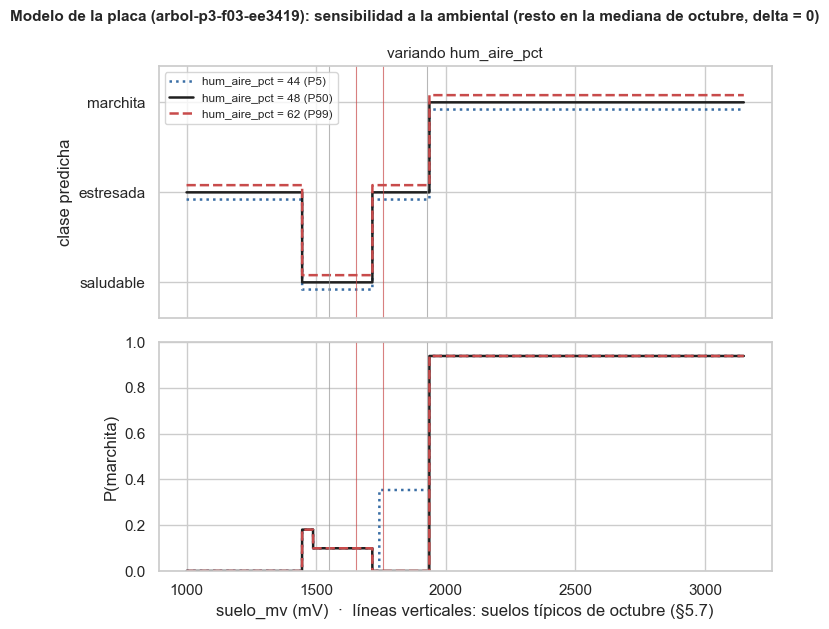

In [26]:
# Figura: clase predicha y P(marchita) contra suelo_mv para tres valores de cada ambiental del modelo
# (percentiles 5, 50 y 99 de lo medido); el resto en la mediana de octubre, delta = 0.
xs_s = np.arange(1000, 3150.25, 0.5).astype(np.float32)
estilos = [("P5", 5, ":", "#3a6ea5"), ("P50", 50, "-", "#1f1f1f"), ("P99", 99, "--", "#c84b4b")]
fig, axes = plt.subplots(2, len(cols_amb), figsize=(7.5 * len(cols_amb), 6.4), sharex=True, squeeze=False,
                         gridspec_kw={"height_ratios": [1.1, 1]})
for j, c in enumerate(cols_amb):
    ax_c, ax_p = axes[0, j], axes[1, j]
    for k, (etq, q, ls, col) in enumerate(estilos):
        v = float(np.percentile(X[:, c], q))
        Xg = np.tile(med_oct, (len(xs_s), 1)).astype(np.float32)
        Xg[:, 0] = xs_s
        Xg[:, c] = v
        pr = modelo.predict(Xg)
        pp = modelo.predict_proba(Xg)
        ax_c.step(xs_s, pr + (k - 1) * 0.08, where="post", ls=ls, color=col, lw=1.8,
                  label=f"{FEATURES[c]} = {v:.3g} ({etq})")
        ax_p.plot(xs_s, pp[:, 2], ls=ls, color=col, lw=1.8)
    for nombre_s, s in SUELOS_OCT.items():
        for ax in (ax_c, ax_p):
            ax.axvline(s, color="#c84b4b" if "marchita" in nombre_s else "#999999", lw=0.8, alpha=0.7)
    ax_c.set_yticks(CODIGOS, CLASES)
    ax_c.set_ylim(0.6, 3.4)
    ax_c.set_title(f"variando {FEATURES[c]}", fontsize=11)
    ax_c.legend(fontsize=8.5, loc="upper left")
    ax_p.set(ylabel="P(marchita)", ylim=(0, 1), xlabel="suelo_mv (mV)  ·  líneas verticales: suelos típicos de octubre (§5.7)")
axes[0, 0].set_ylabel("clase predicha")
fig.suptitle(f"Modelo de la placa ({version}): sensibilidad a la ambiental (resto en la mediana de octubre, delta = 0)",
             fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "modelo_final_sensibilidad.png")
plt.show()

In [27]:
# ¿La ambiental actúa como proxy de la hora del día? La clase está atada a la franja (§6.3).
def cramer_v(a, b):
    t = pd.crosstab(a, b)
    return np.sqrt(stats.chi2_contingency(t)[0] / (t.values.sum() * (min(t.shape) - 1)))


fr = pd.Series(franja)
filas_h = {
    "clase": cramer_v(fr, pd.Series(y)),
    f"predicción sólo suelo ({version_ss})": cramer_v(fr, pd.Series(mdl_ss.predict(X))),
    f"predicción criterio §5.5 ({version_or})": cramer_v(fr, pd.Series(mdl_or.predict(X))),
    f"predicción final ({version})": cramer_v(fr, pd.Series(base_p)),
    "predicción final con las ambientales en la mediana": cramer_v(fr, pd.Series(p_sin)),
}
for c in cols_amb:
    filas_h[f"{FEATURES[c]} (en terciles)"] = cramer_v(fr, pd.Series(pd.qcut(X[:, c], 3, labels=False, duplicates="drop")))
proxy_hora = pd.Series(filas_h, name="V de Cramér con la franja de 3 h").to_frame()
display(proxy_hora)
# A igual sustrato: ¿el modelo predice más marchita de noche que de día por la ambiental?
for nombre_s in ["marchita ep. 12 (mediana)", "entre saludable y marchita"]:
    s = SUELOS_OCT[nombre_s]
    out = {}
    for etq, m in [("noche", octubre & noche), ("día", octubre & ~noche)]:
        Xe = X[m].copy()
        Xe[:, 0] = s
        Xe[:, 1] = 0.0
        pe = modelo.predict(Xe)
        out[etq] = {CLASES[k - 1]: f"{100 * (pe == k).mean():.0f} %" for k in CODIGOS}
    print(f"suelo_mv fijo en {s:.0f} mV ({nombre_s}), ambiente medido de octubre:", out)

,V de Cramér con la franja de 3 h
clase,0.242
predicción sólo suelo (rf-f0-532763),0.155
predicción criterio §5.5 (arbol-p3-f03-ee3419),0.133
predicción final (arbol-p3-f03-ee3419),0.133
predicción final con las ambientales en la mediana,0.127
hum_aire_pct (en terciles),0.592


suelo_mv fijo en 1758 mV (marchita ep. 12 (mediana)), ambiente medido de octubre: {'noche': {'saludable': '0 %', 'estresada': '100 %', 'marchita': '0 %'}, 'día': {'saludable': '0 %', 'estresada': '100 %', 'marchita': '0 %'}}
suelo_mv fijo en 1654 mV (entre saludable y marchita), ambiente medido de octubre: {'noche': {'saludable': '100 %', 'estresada': '0 %', 'marchita': '0 %'}, 'día': {'saludable': '100 %', 'estresada': '0 %', 'marchita': '0 %'}}


**Lectura de §5.7.**

**Comparación con los mismos folds** (sin dudosos):

| modelo | F1 macro | recall marchita | ep. 12 |
|---|---|---|---|
| sólo suelo (RF, `rf-f0-532763`) | 0,678 | 0,52 | 0 % |
| **final (árbol, `arbol-p3-f03-ee3419`)** | 0,711 | 0,69 | 0 % |
| dos umbrales (baseline) | **0,822** | **0,71** | 0 % |

- **Contra el sólo-suelo.** El final gana en F1 (+0,033) y en recall de marchita; en el bootstrap gana en el 74 % de las remuestras. La restricción ya no cuesta F1 contra un RF sólo-suelo.
- **Contra los dos umbrales pierde por 0,11**: la regla ordinal de dos cortes sigue siendo el mejor clasificador de la entrega.
- **El ep. 12 no lo acierta ninguno.**

**¿Influye la humedad del aire? Poco, y sólo en los extremos.**

- **Importancia por permutación.** `hum_aire_pct` baja la exactitud balanceada 0,015 y cambia el 1,5 % de las predicciones. `suelo_mv` la baja 0,47.
- **HR en la mediana.** Cambia la clase del 1,1 % de las filas: 65 filas de 3 episodios, ninguna de noche. Son el **ep. 3** (estresada sobre el radiador, HR ~23 %: 100 % de sus filas pasan de `marchita` a `estresada` correcta), el **ep. 6** (radiador intermitente, 46 %) y el **ep. 13** (5 %: 7 filas del 19/10 con la sonda en ~1940 mV y el aire en 41–43 %, que pasan de `marchita` a `estresada`).
- **Barrido con el suelo de octubre.** Con los suelos típicos (todos ≤ 1936 mV) la HR no cambia la clase: ahí el modelo se comporta como **tres cortes sobre la sonda** (1446, 1716 y 1936 mV).
- **¿Proxy de la hora?** La asociación predicción ~ franja es 0,13 (0,13 también con la HR en la mediana). A sustrato fijo, la predicción es la misma de día y de noche.

**Conclusión.** El modelo cumple la restricción de diseño en la letra: el LED depende de la sonda y de la HR. Pero la HR sólo actúa con el sustrato seco (> 1936 mV) y el aire muy seco (≤ 43,5 %): dice `estresada` en vez de `marchita`. Pasa en el radiador de septiembre y en la tarde del 19/10; con el ambiente típico de octubre no cambia nada.

## 6. Análisis de errores

Por qué falla lo que falla: episodio por episodio, la frontera sobre `suelo_mv`, la deriva de la sonda y la hora del día. Después, la pregunta binaria y una prueba con datos que el modelo nunca vio.

### 6.1 El modelo final, episodio por episodio

Proporción de filas de cada episodio que el modelo final asigna a cada clase (entrenado con todos los episodios, como va a la placa) y el acierto fuera de fold (cada episodio predicho por un modelo que no lo vio). Agregados por episodio.

In [28]:
filas_tab = []
for e, d in df.groupby("episodio_id"):
    idx = d.index.to_numpy()
    fila = {"episodio": e, "clase": d.clase.iloc[0], "dudoso": bool(d.dudoso.iloc[0]), "filas": len(d),
            "suelo_mv_mediana": d.suelo_mv.median()}
    for c, nombre in zip(CODIGOS, CLASES):
        fila[f"final→{nombre[:5]}"] = (base_p[idx] == c).mean()
    fila["acierto final (train)"] = (base_p[idx] == y[idx]).mean()
    fila["acierto fuera de fold"] = (oof_fija[idx] == y[idx]).mean()
    filas_tab.append(fila)
por_ep = pd.DataFrame(filas_tab).set_index("episodio")
display(por_ep)
ok = por_ep["acierto fuera de fold"] > 0.5
print(f"episodios con más de la mitad de las filas bien (fuera de fold): {ok.sum()} de {len(por_ep)}; "
      f"sin dudosos: {ok[~por_ep.dudoso].sum()} de {(~por_ep.dudoso).sum()}")

,clase,dudoso,filas,suelo_mv_mediana,final→salud,final→estre,final→march,acierto final (train),acierto fuera de fold
episodio,,,,,,,,,
1,marchita,False,132,"2,832.000",0.000,0.000,1.000,1.000,1.000
3,estresada,False,24,"2,766.500",0.000,1.000,0.000,1.000,1.000
6,estresada,False,74,"2,048.000",0.000,0.514,0.486,0.514,0.270
8,marchita,True,111,"1,518.000",1.000,0.000,0.000,0.000,0.000
9,estresada,True,52,"1,454.000",1.000,0.000,0.000,0.000,0.000
10,saludable,False,140,"1,504.000",0.950,0.050,0.000,0.950,0.771
11,saludable,True,27,"1,785.500",0.000,1.000,0.000,0.000,0.000
12,marchita,False,90,"1,758.000",0.000,1.000,0.000,0.000,0.000
13,estresada,False,146,"1,927.000",0.000,0.815,0.185,0.815,0.616


episodios con más de la mitad de las filas bien (fuera de fold): 13 de 24; sin dudosos: 13 de 20


### 6.2 La frontera sobre `suelo_mv` y la deriva de la sonda

Distribución de `suelo_mv` por clase, con los cortes del modelo final (las ambientales en su mediana). Cómo los corre la ambiental está en §5.7.

figura: docs/entrega2/fig/fronteras_suelo_mv.png


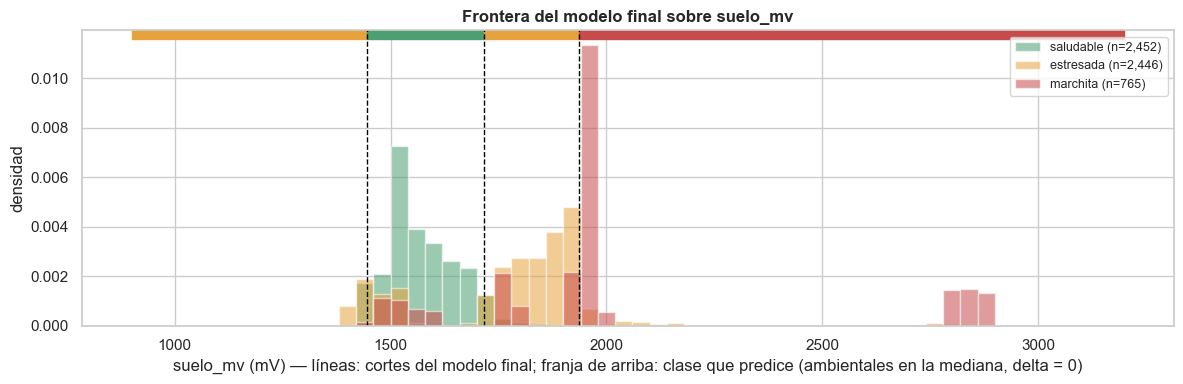

cambios de clase sobre suelo_mv (mV): [1446.0, 1716.75, 1936.75]


In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.arange(900, 3200, 40)
for c in CLASES:
    v = df.loc[df.clase == c, "suelo_mv"]
    ax.hist(v, bins=bins, density=True, alpha=0.55, color=COLORES[c], label=f"{c} (n={len(v):,})")
for u in umbrales_final:
    ax.axvline(u, color="black", ls="--", lw=1)
for t in tramos:
    ax.axvspan(xs[t[0]], xs[t[-1]], ymin=0.97, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
ax.set_ylabel("densidad")
ax.legend(fontsize=9, loc="upper right")
ax.set_xlabel("suelo_mv (mV) — líneas: cortes del modelo final; franja de arriba: clase que predice "
              "(ambientales en la mediana, delta = 0)")
ax.set_title("Frontera del modelo final sobre suelo_mv", fontweight="bold")
fig.tight_layout()
guardar(fig, "fronteras_suelo_mv.png")
plt.show()
print("cambios de clase sobre suelo_mv (mV):", [round(u, 2) for u in umbrales_final])

In [30]:
# Deriva de la sonda: el mismo estado de la planta, otra lectura según el período.
PERIODOS = [("13–17/09", "2026-09-01", "2026-10-01"), ("01–03/10", "2026-10-01", "2026-10-03T21:00"),
            ("03–18/10", "2026-10-03T21:00", "2026-10-18T23:30"), ("19–21/10", "2026-10-18T23:30", "2026-11-01")]
periodo = pd.Series(pd.NA, index=df.index, dtype=object)
for nombre_p, a, b in PERIODOS:
    periodo[(df.ts >= pd.Timestamp(a, tz="UTC")) & (df.ts < pd.Timestamp(b, tz="UTC"))] = nombre_p
r = df.assign(periodo=pd.Categorical(periodo, [p[0] for p in PERIODOS], ordered=True))
display(r.groupby(["clase", "periodo"], observed=True).agg(episodios=("episodio_id", "nunique"), filas=("ts", "size"),
                                                          suelo_mv_mediana=("suelo_mv", "median"))
        .unstack("periodo").reindex(CLASES))

episodios                               filas                             suelo_mv_mediana                              
periodo    13–17/09 01–03/10 03–18/10 19–21/10 13–17/09 01–03/10  03–18/10 19–21/10         13–17/09  01–03/10  03–18/10  19–21/10
clase                                                                                                                             
saludable       NaN    1.000    4.000    2.000      NaN  140.000 2,026.000  286.000              NaN 1,504.000 1,569.500 1,456.250
estresada     2.000    1.000    6.000    2.000   98.000   52.000 1,848.000  448.000        2,064.000 1,454.000 1,836.500 1,461.000
marchita      1.000    1.000    3.000    1.000  132.000  111.000   432.000   90.000        2,832.000 1,518.000 1,954.000 1,758.000

### 6.3 ¿La clase sigue a la hora del día?

La hora no es feature, pero si la clase está atada al reloj, la luz y la temperatura pueden colarla. Se mide la asociación entre la franja horaria (8 franjas de 3 h, hora local UTC−3) y la clase con la V de Cramér: 0 = independientes, 1 = la franja determina la clase.

V de Cramér franja horaria × clase: 0.24
  predicción del modelo final: 0.13
  predicción del modelo sólo-suelo (rf-f0-532763): 0.15
Mediana de luz_mv por clase:


,luz_mv
clase,
saludable,973.000
estresada,"1,201.000"
marchita,277.500


figura: docs/entrega2/fig/clase_por_hora.png


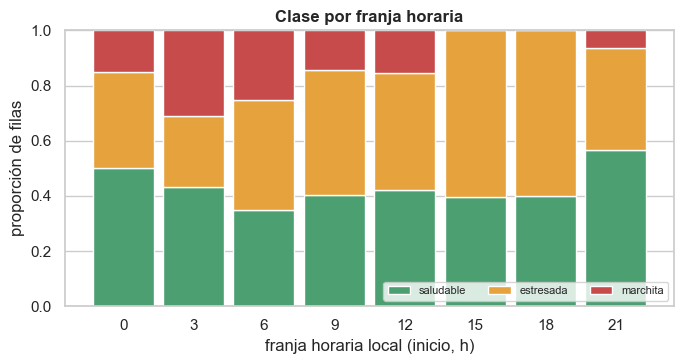

In [31]:
print(f"V de Cramér franja horaria × clase: {cramer_v(fr, pd.Series(y)):.2f}")
print(f"  predicción del modelo final: {cramer_v(fr, pd.Series(base_p)):.2f}")
print(f"  predicción del modelo sólo-suelo ({version_ss}): {cramer_v(fr, pd.Series(mdl_ss.predict(X))):.2f}")
print("Mediana de luz_mv por clase:")
display(df.groupby("clase").luz_mv.median().reindex(CLASES).to_frame())

fig, ax = plt.subplots(figsize=(7, 3.8))
p = pd.crosstab(franja, df.clase, normalize="index").reindex(columns=CLASES).fillna(0)
base = np.zeros(len(p))
for c in CLASES:
    ax.bar(p.index, p[c], 2.6, bottom=base, color=COLORES[c], label=c)
    base += p[c].values
ax.set(xlabel="franja horaria local (inicio, h)", xticks=range(0, 24, 3), ylabel="proporción de filas")
ax.legend(ncol=3, fontsize=8, loc="lower right")
ax.set_title("Clase por franja horaria", fontweight="bold")
fig.tight_layout()
guardar(fig, "clase_por_hora.png")
plt.show()

**¿Qué pasa si se deja entrar la luz?** La luz no está entre las ambientales permitidas. Se decidió **después de ver resultados** con sólo `maceta-01`: con la luz, las únicas configuraciones que pasaban la condición de seguridad eran regresiones logísticas con `luz_media_1h`, y marcaban `marchita` casi todas las noches de una planta sana. La celda las reentrena con los 24 episodios y las prueba sobre las noches de los datos sin etiqueta del 21–22/10 (§6.5), con la planta presumiblemente `saludable`.

In [32]:
CORTE_01 = df.ts.max()     # última fila con episodio (fin del ep. 15)
nuevo_l = serie_maceta01(filtrado=False)
nuevo_l = nuevo_l[(nuevo_l.ts > CORTE_01) & nuevo_l.valido & ~nuevo_l.post_boot & ~nuevo_l.suelo_saturado]
Xl = matriz_X(nuevo_l)
hl = (nuevo_l.ts - pd.Timedelta(hours=3)).dt.hour
noche_l = ((hl >= 22) | (hl < 8)).to_numpy()
filas_luz = {}
for cols in [(0, 6), (0, 5, 6), (0, 5)]:
    for c_ in (0.01, 0.1, 1.0):
        est_l = clone(MODELOS["Regresión logística"][0]).set_params(sel__columnas=cols, clf__C=c_)
        oof_l = np.zeros(len(y), int)
        for tr, te in folds_ext:
            oof_l[te] = clone(est_l).fit(X[tr], y[tr]).predict(X[te])
        m_l = clone(est_l).fit(X, y)
        p_l = m_l.predict(Xl)
        filas_luz[f"[{nombre_subconjunto(cols)}] C={c_}"] = {
            "F1 sin dudosos": f1m(y[sin_dud], oof_l[sin_dud]),
            "recall marchita sin dudosos": recall_marchita(y[sin_dud], oof_l[sin_dud]),
            "ep. 12": (oof_l[e12] == 3).mean(),
            "% marchita en saludables de noche (train)": 100 * (m_l.predict(X[(y == 1) & noche]) == 3).mean(),
            "% marchita, datos nuevos de noche": 100 * (p_l[noche_l] == 3).mean(),
            "% marchita, datos nuevos de día": 100 * (p_l[~noche_l] == 3).mean()}
tabla_luz = pd.DataFrame(filas_luz).T
display(tabla_luz)

,F1 sin dudosos,recall marchita sin dudosos,ep. 12,% marchita en saludables de noche (train),"% marchita, datos nuevos de noche","% marchita, datos nuevos de día"
[suelo_mv+luz_media_1h] C=0.01,0.619,0.645,0.867,8.605,0.000,0.000
[suelo_mv+luz_media_1h] C=0.1,0.608,0.604,0.544,6.975,0.000,0.000
[suelo_mv+luz_media_1h] C=1.0,0.607,0.601,0.511,6.884,0.000,0.000
[suelo_mv+luz_mv+luz_media_1h] C=0.01,0.612,0.607,0.556,7.337,0.000,0.000
[suelo_mv+luz_mv+luz_media_1h] C=0.1,0.607,0.566,0.333,4.167,0.000,0.000
[suelo_mv+luz_mv+luz_media_1h] C=1.0,0.605,0.557,0.322,3.080,0.000,1.316
[suelo_mv+luz_mv] C=0.01,0.602,0.560,0.111,4.620,0.000,0.000
[suelo_mv+luz_mv] C=0.1,0.597,0.552,0.044,2.446,0.000,0.000
[suelo_mv+luz_mv] C=1.0,0.598,0.552,0.044,2.174,0.000,0.000


**Lectura de §6.1–§6.3.**

- **Por episodio, fuera de fold**, acierta más de la mitad de las filas en 13 de los 20 no dudosos. Casi todos los del 03/10 al 18/10, salvo el 18 (marchita, 40 %) y las recuperaciones post-riego.
  - Fallan siempre los eps. **19, 23 y 27** (estresada post-riego con el sustrato ya en ~1490–1520 mV): el modelo dice `saludable`. La planta tarda horas en recuperar turgencia después del riego y la sonda no lo ve.
  - Falla el **12**: la marchita del 19/10 a 1758 mV, que cae en la zona `estresada`.
  - Fallan el **6** (27 %) y el **15** (33 %): sin ese episodio en el train el corte se mueve.
  - Fallan todos los dudosos (8, 9, 11 y 14), cuya etiqueta contradice al sustrato.
- **La frontera** son tres cortes en ~1446, ~1716 y ~1936 mV (con la HR en la mediana). El de 1936 mV separa estresada de marchita en los ciclos del 03/10 al 18/10 casi perfecto.
- **Deriva de la sonda.** La marchita lee 2832 mV en septiembre, ~1954 mV del 03/10 al 18/10, 1518 mV el 01/10 (el dudoso 8) y 1758 mV el 19/10. La misma condición lee ~900 mV distinto según el mes.
- **La hora.**
  - La asociación clase ~ franja horaria baja de 0,47 a **0,24**: las marchitas del 03/10 al 18/10 son diurnas (03–15 h local). La confusión clase ↔ horario del observador se rompe en parte.
  - **Con luz, las regresiones logísticas ya no pasan la condición de seguridad** (recall de marchita 0,55–0,65, F1 ≤ 0,62) y en las noches de los datos sin etiqueta del 21–22/10 ninguna predice `marchita`. La exclusión de la luz (decidida después de ver resultados con el snapshot del 21/10) ya no le cuesta nada al modelo.

### 6.4 Análisis secundario: binario *requiere cuidado*

`estresada` ∪ `marchita` contra `saludable`. No es el modelo de la placa (que es de 3 clases): sirve para ver si al menos la pregunta gruesa "¿hay que hacer algo?" se puede contestar. Mismo protocolo por episodio, con los baselines y tres candidatos baratos de exportar (árbol, regresión logística, Naive Bayes).

In [33]:
yb = (y >= 2).astype(int)        # 1 = requiere cuidado


def evaluar_binario(est, grilla):
    oof = np.zeros(len(yb), int)
    oof_p = np.full(len(yb), np.nan)
    for tr, te in folds_ext:   # mismos folds que §4 (estratificados en 3 clases)
        if grilla:
            mdl = busqueda(est, grilla).fit(X[tr], yb[tr], groups=g[tr]).best_estimator_
        else:
            mdl = clone(est).fit(X[tr], yb[tr])
        oof[te] = mdl.predict(X[te])
        if hasattr(mdl, "predict_proba") and 1 in mdl.classes_:
            oof_p[te] = mdl.predict_proba(X[te])[:, list(mdl.classes_).index(1)]
    return oof, oof_p


filas_bin = {}
for n in ["Clase mayoritaria", "Umbral único (suelo_mv)", "Árbol de decisión", "Regresión logística", "Naive Bayes"]:
    oof_b, oof_bp = evaluar_binario(*MODELOS[n])
    fila = {}
    for mk, m in MASCARAS_EV.items():
        fila[f"exactitud_bal ({mk})"] = balanced_accuracy_score(yb[m], oof_b[m])
        fila[f"recall_cuidado ({mk})"] = recall_score(yb[m], oof_b[m], zero_division=0)
        fila[f"roc_auc ({mk})"] = roc_auc_score(yb[m], oof_bp[m]) if np.isfinite(oof_bp[m]).all() else np.nan
    filas_bin[n] = fila
tabla_binaria = pd.DataFrame(filas_bin).T
display(tabla_binaria)

,exactitud_bal (todos),recall_cuidado (todos),roc_auc (todos),exactitud_bal (sin dudosos),recall_cuidado (sin dudosos),roc_auc (sin dudosos)
Clase mayoritaria,0.328,0.599,0.328,0.315,0.572,0.315
Umbral único (suelo_mv),0.856,0.749,0.846,0.924,0.876,0.926
Árbol de decisión,0.821,0.814,0.870,0.873,0.908,0.926
Regresión logística,0.818,0.789,0.785,0.887,0.918,0.907
Naive Bayes,0.786,0.683,0.799,0.847,0.795,0.878


**Binario.** La pregunta gruesa "¿hay que hacer algo?" sale bastante bien.

- **Sin dudosos**, el umbral único sobre `suelo_mv` da 0,924 de exactitud balanceada (ROC-AUC 0,93), el árbol 0,873 (ROC-AUC 0,93) y la regresión logística 0,887.
- **Con todos los episodios** baja a 0,79–0,86: los dudosos 8, 9 y 14 piden cuidado con el sustrato de una saludable.
- Para la decisión de riego, un solo corte sobre la sonda alcanza; lo difícil es separar `estresada` de `marchita`.

### 6.5 Prueba con datos sin etiqueta de Railway

El snapshot del 23/10 trae, después del ep. 15, 2.740 filas crudas (21/10 21:25 → 22/10 20:00 UTC) que **ningún episodio cubre**: la placa las mandó con `saludable` **propagada** de la pulsación del 20/10 y nadie miró la planta. Se pasan por el mismo `serie_maceta01` (remuestreo, features, filtros de calidad) y se predicen con el modelo final.

Límite: es una prueba de estabilidad sobre un tramo presumiblemente `saludable`, no una evaluación de las tres clases. No se suman al entrenamiento. (Las 9 filas siguientes, con el firmware 2.0.0 recién flasheado, tienen casi todas la sonda saturada y quedan afuera por el filtro de calidad.)

filas nuevas (5 min): 272, del 21/10 21:25 al 22/10 20:00 UTC; sin episodio asignado
etiqueta que mandó la placa (filas crudas a 30 s): {('estresada', 'manual'): 1, ('saludable', 'propagada'): 2708}


,saludable,estresada,marchita
modelo final,272,0,0


,count,mean,std,min,25%,50%,75%,max
suelo_mv,272.000,"1,516.210",18.300,"1,496.000","1,504.000","1,504.500","1,529.000","1,563.000"
vpd_kpa,272.000,1.170,0.120,0.760,1.120,1.200,1.240,1.360
temp_c,272.000,21.090,0.740,19.400,20.600,21.000,21.800,22.200
hum_aire_pct,272.000,53.330,3.790,45.000,51.000,53.500,55.000,67.000
luz_mv,272.000,"1,017.720",776.680,142.000,142.000,"1,226.250","1,733.250","2,521.500"


figura: docs/entrega2/fig/prueba_railway_nuevos.png


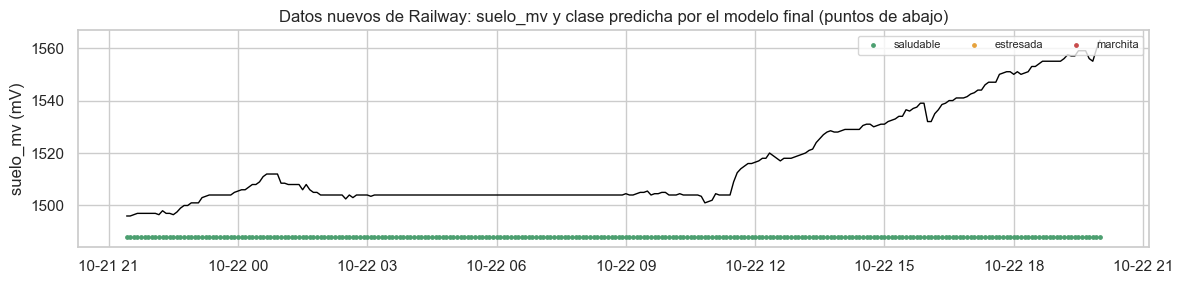

In [34]:
SNAPSHOT_NUEVO = SNAPSHOT_VIGENTE
corte = CORTE_01             # última fila con episodio (fin del ep. 15)
nuevo = serie_maceta01(snapshot=SNAPSHOT_NUEVO, filtrado=False)
nuevo = nuevo[(nuevo.ts > corte) & nuevo.valido & ~nuevo.post_boot & ~nuevo.suelo_saturado]
Xn = matriz_X(nuevo)
print(f"filas nuevas (5 min): {len(nuevo)}, del {nuevo.ts.min():%d/%m %H:%M} al {nuevo.ts.max():%d/%m %H:%M} UTC; "
      f"sin episodio asignado")
crudo_nuevo = pd.read_csv(SNAPSHOT_NUEVO)
crudo_nuevo = crudo_nuevo[pd.to_datetime(crudo_nuevo.ts_servidor, format="ISO8601", utc=True) > corte]
print("etiqueta que mandó la placa (filas crudas a 30 s):",
      crudo_nuevo.groupby(["condicion_etiqueta", "etiqueta_origen"]).size().to_dict())

assert version_modelo(modelo) == version
pred_nuevo = pd.Series(modelo.predict(Xn)).replace(dict(enumerate(CLASES, 1)))
display(pred_nuevo.value_counts().reindex(CLASES).fillna(0).astype(int).rename("modelo final").to_frame().T)
display(nuevo[["suelo_mv", "vpd_kpa", "temp_c", "hum_aire_pct", "luz_mv"]].describe().round(2).T)

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(nuevo.ts, nuevo.suelo_mv, color="black", lw=1)
for clase_n in CLASES:
    mask_n = (pred_nuevo == clase_n).to_numpy()
    ax.scatter(nuevo.ts[mask_n], np.full(mask_n.sum(), nuevo.suelo_mv.min() - 8), s=6, color=COLORES[clase_n],
               label=clase_n)
ax.set_ylabel("suelo_mv (mV)")
ax.legend(fontsize=8, ncol=3, loc="upper right")
ax.set_title("Datos nuevos de Railway: suelo_mv y clase predicha por el modelo final (puntos de abajo)")
fig.tight_layout()
guardar(fig, "prueba_railway_nuevos.png")
plt.show()

## 7. Resumen de números y discusión

La celda siguiente junta los números clave **calculados en esta ejecución** y escribe todas las tablas en `docs/entrega2/tablas_03_modelos.md` (generado, no editar): si cambian los datos y se re-ejecuta el notebook, el resumen y las tablas se actualizan solos.

In [35]:
def fmt(v):
    return f"{v:.3f}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)


def con_desv(n, mk, met):
    return f"{fmt(resumen_cv.loc[n, (mk, met)])} ± {fmt(resumen_cv.loc[n, (mk, met + ' (desvío)')])}"


clave = {
    "snapshot": SNAPSHOT_VIGENTE.name,
    "filas / episodios": f"{len(df):,} / {df.episodio_id.nunique()}",
    "filas / episodios sin dudosos": f"{sin_dud.sum():,} / {df[sin_dud].episodio_id.nunique()}",
    "episodios dudosos": str(sorted(EPISODIOS_DUDOSOS)),
    "fuga: RF 7 features, aleatoria vs por episodio": " vs ".join(fmt(v) for v in fuga.iloc[0].values),
    "criterio §5.3 en el espacio restringido (sin seguridad)": f"{tipo_original} {describir(config_original)}",
    "elegido tras la condición de seguridad": f"{final_tipo} {describir(final_params)}"
        + (" (ninguna configuración la cumple: queda la de §5.5)" if aptas.empty else ""),
    "config final": f"{CONFIG_FINAL['tipo']} {describir(CONFIG_FINAL['params'])}",
    "coincide con CONFIG_FINAL": coincide,
    "versión": version,
    "header al día": version == en_header,
    "F1 macro sin dudosos, búsqueda anidada del tipo final": con_desv(CONFIG_FINAL["tipo"], "sin dudosos", "f1_macro"),
    "F1 macro sin dudosos, dos umbrales": con_desv(DU, "sin dudosos", "f1_macro"),
    "config. final fija: F1 macro (todos / sin dudosos)":
        f"{fmt(fija['metricas'][('todos', 'f1_macro')])} / {fmt(fija['metricas'][('sin dudosos', 'f1_macro')])}",
    "config. final fija: exactitud bal. (todos / sin dudosos)":
        f"{fmt(fija['metricas'][('todos', 'exactitud_bal')])} / {fmt(fija['metricas'][('sin dudosos', 'exactitud_bal')])}",
    "config. final fija: recall marchita (todos / sin dudosos)":
        f"{fmt(fija['metricas'][('todos', 'recall_marchita')])} / {fmt(fija['metricas'][('sin dudosos', 'recall_marchita')])}",
    "config. final fija: exactitud bal. (todos / sin dud. / sin 13 / sin dud. ni 13)":
        " / ".join(fmt(comparacion.loc[(k_nv, k), "exactitud_bal"]) for k in MASCARAS),
    "costo elegido": str(costo_esp32(modelo)),
    "restricción de diseño": "suelo_mv + al menos una ambiental en todos los candidatos con selección",
    "features del modelo final": ", ".join(FEATURES[c] for c in modelo.named_steps["sel"].columnas),
    "% filas que cambian con la ambiental en la mediana": fmt(pct_cambio_final),
    "configuraciones exploradas / que pasan costo + influencia + seguridad":
        f"{len(explor)} / {int(explor.pasa_filtros.sum())}",
    "puntaje config. fija: sólo suelo / criterio §5.5 / final / dos umbrales":
        " / ".join(fmt(v) for v in resumen_cmp["puntaje (F1 sin dudosos)"]),
    "V de Cramér franja ~ clase / predicción final / sólo suelo":
        " / ".join(fmt(proxy_hora.loc[k].iloc[0]) for k in ["clase", f"predicción final ({version})",
                                                               f"predicción sólo suelo ({version_ss})"]),
    "datos sin etiqueta 21–22/10: filas / predicción": f"{len(nuevo)} / {pred_nuevo.value_counts().to_dict()}",
}
display(pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame())

secciones = {
    "Conteo de filas y episodios": tabla_conteo,
    "Episodios": tabla_ep,
    "Fuga: partición aleatoria vs por episodio (exactitud balanceada)": fuga,
    "Partición por episodio, fuera de fold (± desvío bootstrap por episodio)": tabla_cv,
    "Costo estimado en la ESP32": costo[["config", "flash_B", "ram_B", "ops", "exps", "t_us_est", "exportable"]],
    **{f"Sensibilidad a dudosos y al ep. 13 — {m}": sensibilidad[m].unstack("episodios").reindex(index=orden, columns=list(MASCARAS))
       for m in METRICAS},
    "Selección (criterio §5.3)": sel,
    "Elegido vs baselines": comp,
    "Restricción de diseño — configuraciones probadas (compuerta de influencia ambiental)": tabla_probadas,
    "Condición de seguridad — embudo por tipo": embudo,
    "Condición de seguridad — todas las configuraciones": tabla_candidatos_seg,
    "Configuraciones del tipo elegido": pd.DataFrame(filas_cfg).T,
    **{f"Restricción de diseño — sólo suelo vs criterio §5.5 vs final vs dos umbrales — {m}":
       comparacion[m].unstack("episodios")[list(MASCARAS)] for m in METRICAS},
    "Restricción de diseño — resumen": resumen_cmp,
    "Influencia ambiental — importancia por permutación": importancia,
    "Influencia ambiental — ambiental en la mediana": cambio_mediana,
    "Influencia ambiental — por episodio": cambios_ep,
    "Influencia ambiental — barrido con suelo de octubre": tabla_barrido.set_index(["ambiental", "suelo_mv fijo"]),
    "¿Proxy de la hora? (V de Cramér con la franja)": proxy_hora,
    "Luz como proxy de la hora — regresiones logísticas con luz": tabla_luz,
    "Modelo final por episodio": por_ep,
    "Binario requiere cuidado": tabla_binaria,
    "Números clave": pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame(),
}
partes = ["<!-- GENERADO por notebooks/03_modelos.ipynb — no editar; se reescribe al re-ejecutar. -->",
          "# Tablas del notebook 03_modelos", "",
          f"Datos: `{SNAPSHOT_VIGENTE.name}` (sólo lo medido por la placa). Modelo: `{version}`.", ""]
for titulo, t in secciones.items():
    t = t.copy()
    partes += [f"## {titulo}", "", t.to_markdown(floatfmt=".3f") if hasattr(t, "to_markdown") else str(t), ""]
SALIDA_TABLAS.write_text("\n".join(partes), encoding="utf-8")
print(f"tablas: {SALIDA_TABLAS.relative_to(RAIZ)}")

,valor
snapshot,mediciones_raw_2026-10-23.csv
filas / episodios,"5,663 / 24"
filas / episodios sin dudosos,"5,171 / 20"
episodios dudosos,"[8, 9, 11, 14]"
"fuga: RF 7 features, aleatoria vs por episodio",0.968 vs 0.646
criterio §5.3 en el espacio restringido (sin seguridad),"Árbol de decisión [suelo+hr] max_depth=3, min_..."
elegido tras la condición de seguridad,"Árbol de decisión [suelo+hr] max_depth=3, min_..."
config final,"Árbol de decisión [suelo+hr] max_depth=3, min_..."
coincide con CONFIG_FINAL,True
versión,arbol-p3-f03-ee3419


tablas: docs/entrega2/tablas_03_modelos.md


### Discusión

**Qué se entrenó.** Sólo lo medido: 5.663 filas de 5 min en 24 episodios (20 sin dudosos). Con un split aleatorio cualquier modelo parece excelente (0,97); por episodio, el mejor candidato llega a F1 macro 0,78 y la regla de dos umbrales sobre la sonda a 0,82. Pasar de 11 a 24 episodios es lo que más cambió el resultado: con el snapshot del 21/10 nada generalizaba (F1 ≈ 0,3).

**Ventajas del modelo elegido** (`arbol-p3-f03-ee3419`, árbol de profundidad 3 con `suelo_mv` y `hum_aire_pct`)

- **Se lee entero**: tres cortes sobre la sonda y un ajuste por aire muy seco.
- **Cumple la restricción de producto**: el LED depende de la sonda y del aire (HR).
- **No usa la luz ni la hora**: la predicción casi no se asocia con la franja horaria (V de Cramér 0,13). Sobre los datos sin etiqueta del 21–22/10 da `saludable` en el 100 % de las filas, de día y de noche.
- **Barato**: 231 B de tablas, 3 comparaciones, sin memoria dinámica. Paridad Python ↔ C del 100 % en `pio test`.

**Memoria y CPU en la ESP32**

- **Flash.** 231 B de tablas; el firmware completo usa el 73,4 % de la flash de la placa.
- **Inferencia.** 3 comparaciones por predicción (profundidad 3), 0–1 µs medidos en el host. Una vez cada 5 min.
- **RAM.** 16 B de trabajo más el buffer de 13 muestras.

**Limitaciones**

1. **Pierde contra el baseline.** Los dos umbrales sobre `suelo_mv` dan 0,822 de F1 macro sin dudosos; el árbol de la placa (configuración fija) 0,711 ± 0,053. La restricción "suelo + ambiental" y la compuerta de influencia cuestan ~0,1 de F1.
2. **La ambiental es casi decorativa.** La HR cambia el 1,1 % de las filas: el radiador de septiembre y 7 filas del 19/10 con el aire en 41–43 %. Con el ambiente típico de octubre el modelo es un umbral triple sobre la sonda.
3. **No reconoce la recuperación post-riego** (eps. 19, 23, 27) ni la marchita del 19/10 (ep. 12). La condición de seguridad no la cumple ningún modelo.
4. **El tramo del 03/10 al 18/10 pesa mucho**: 4.306 de las 5.663 filas y 13 de los 24 episodios, con tres ciclos casi idénticos. Los cortes de 1716 y 1936 mV son los de la sonda en esas dos semanas; con la sonda más corroída no tienen por qué valer.
5. **El criterio se completó después de ver resultados** (compuerta de influencia, condición de seguridad y exclusión de la luz, fijadas con el snapshot del 21/10). No se tocaron en esta re-ejecución.
6. **La sonda deriva.** La misma condición lee ~900 mV distinto entre septiembre y octubre. Hace falta la calibración semanal de `docs/CALIBRACION.md`.

**Mejoras posibles**

- **Más episodios observados**, sobre todo con ambiente distinto, para que la ambiental tenga algo que aprender y los cortes no dependan de dos semanas de la sonda.
- **Modelar la recuperación post-riego** con una feature de tiempo desde el último salto brusco del sustrato (un riego se ve como −400 mV en una muestra).
- **Normalizar la sonda** con la calibración semanal, o pasar a una sonda capacitiva.
- **Persistir las predicciones** en el backend para evaluar el modelo en línea contra observaciones nuevas.